# Predicting Run vs. Pass from Pre-Snap NFL Data
**CS 363M Machine Learning, Fall 2026**

## §0 Introduction
Before every snap, the defense has to guess: run or pass? We build a model that makes that guess using only information available **before the snap**: down, distance, field position, clock, score, weather, and how both teams lined up.

**Data.** Two nflverse datasets from the 2022 season:
- **Play-by-play (pbp):** ~370 columns per play (situation, clock, score, weather, outcome).
- **Participation:** formation, personnel and defenders in the box (from NFL Next Gen Stats), plus some post-snap columns we don't use.

**Task.** Binary classification on scrimmage plays: `is_pass = 1` for called passes (dropbacks), `0` for designed runs.
- **Sacks and scrambles count as passes**, because the offense called a pass.
- **Scrimmage plays only.** Our proposal said "pass vs. anything else", but punts and field goals are trivially predictable from 4th down and formation, so they would inflate accuracy. Kneels and spikes are clock management, so they are out too.

**Contents:** 1. Data and merge · 2. Cleaning · 3. Exploratory analysis · 4. Feature engineering · 5. Train/test split and cross-validation · 6. Modeling · 7. Results

In [1]:
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 50)
RANDOM_STATE = 363

## §1 Data acquisition and merge

### 1.1 Download
We download both parquet files from the `nflverse-data` GitHub releases and cache them in `data/` (gitignored). Parquet keeps column types and loads much faster than CSV.

In [2]:
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
BASE_URL = "https://github.com/nflverse/nflverse-data/releases/download"
FILES = {
    "pbp":  ("pbp", "play_by_play_2022.parquet"),
    "part": ("pbp_participation", "pbp_participation_2022.parquet"),
}

def fetch(release: str, fname: str) -> Path:
    """Download a file from an nflverse-data release unless it is already cached."""
    path = DATA_DIR / fname
    if not path.exists():
        print(f"Downloading {fname} ...")
        urllib.request.urlretrieve(f"{BASE_URL}/{release}/{fname}", path)
    return path

pbp  = pd.read_parquet(fetch(*FILES["pbp"]))
part = pd.read_parquet(fetch(*FILES["part"]))
print(f"pbp:           {pbp.shape[0]:>6,} rows x {pbp.shape[1]} cols")
print(f"participation: {part.shape[0]:>6,} rows x {part.shape[1]} cols")

pbp:           49,434 rows x 372 cols
participation: 50,150 rows x 20 cols


In [3]:
part.head(3)

,nflverse_game_id,old_game_id,play_id,possession_team,offense_formation,offense_personnel,defenders_in_box,defense_personnel,number_of_pass_rushers,players_on_play,offense_players,defense_players,n_offense,n_defense,ngs_air_yards,time_to_throw,was_pressure,route,defense_man_zone_type,defense_coverage_type
0,2022_01_BUF_LA,2022090800,1,,NaN,NaN,NaN,NaN,NaN,,,,0,0,NaN,NaN,None,NaN,NaN,NaN
1,2022_01_BUF_LA,2022090800,41,LA,NaN,NaN,NaN,NaN,NaN,52512;42818;48482;52835;48772;54696;48011;5284...,00-0036421;00-0035933;00-0035609;00-0035942;00...,00-0031787;00-0035352;00-0037318;00-0035308;00...,11,11,NaN,NaN,None,NaN,NaN,NaN
2,2022_01_BUF_LA,2022090800,56,BUF,SHOTGUN,"1 RB, 1 TE, 3 WR",6.0,"3 DL, 3 LB, 5 DB",4.0,42816;48512;43298;47844;43335;47879;44875;4791...,00-0035382;00-0035689;00-0033904;00-0027648;00...,00-0031785;00-0033072;00-0035663;00-0032889;00...,11,11,4.52,2.169,False,IN,ZONE_COVERAGE,COVER_6


### 1.2 Join keys
The game key has a different name in each table and pbp stores `play_id` as a float, so we align them first. We also check that each table has exactly one row per play; otherwise the join would duplicate plays.

In [4]:
pbp["play_id"] = pbp["play_id"].astype("int64")
part["play_id"] = part["play_id"].astype("int64")
part = part.rename(columns={"nflverse_game_id": "game_id"})

KEYS = ["game_id", "play_id"]
assert not pbp.duplicated(KEYS).any(), "duplicate keys in pbp"
assert not part.duplicated(KEYS).any(), "duplicate keys in participation"
print("Games in pbp:", pbp.game_id.nunique(), "| games in participation:", part.game_id.nunique())
print("Season types in pbp:", pbp.season_type.value_counts().to_dict())

Games in pbp: 284 | games in participation: 284
Season types in pbp: {'REG': 47157, 'POST': 2277}


### 1.3 Join diagnostics
An outer join shows what each side would lose before we do the real join.

In [5]:
diag = pbp[KEYS].merge(part[KEYS + ["offense_formation", "n_offense"]],
                       on=KEYS, how="outer", indicator=True)
print(diag["_merge"].value_counts().rename({"left_only": "pbp only",
                                            "right_only": "participation only",
                                            "both": "matched"}))

part_only = diag[diag["_merge"] == "right_only"]
print(f"\nParticipation-only rows with a formation recorded: {part_only.offense_formation.notna().sum()}")
print(f"Participation-only rows with any offensive players:  {(part_only.n_offense > 0).sum()}")

_merge
matched               49434
participation only      716
pbp only                  0
Name: count, dtype: int64

Participation-only rows with a formation recorded: 0
Participation-only rows with any offensive players:  0


**Takeaway.** Every pbp play has a match. The 716 participation-only rows are empty placeholders (no formation, personnel or players), so we lose nothing.

### 1.4 Inner join
We need both tables for our best features, so we keep only matched plays (here: all of them). We drop participation's duplicate `old_game_id` first.

In [6]:
df = pbp.merge(part.drop(columns=["old_game_id"]), on=KEYS, how="inner", validate="one_to_one")

assert len(df) == len(pbp), "inner join should keep every pbp play"
assert not df.duplicated(KEYS).any()
print(f"Merged: {df.shape[0]:,} rows x {df.shape[1]} cols")
df[["game_id", "play_id", "posteam", "down", "ydstogo", "play_type",
    "offense_formation", "offense_personnel", "defenders_in_box", "defense_personnel"]].head()

Merged: 49,434 rows x 389 cols


,game_id,play_id,posteam,down,ydstogo,play_type,offense_formation,offense_personnel,defenders_in_box,defense_personnel
0,2022_01_BAL_NYJ,1,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN
1,2022_01_BAL_NYJ,43,NYJ,NaN,0.0,kickoff,NaN,NaN,NaN,NaN
2,2022_01_BAL_NYJ,68,NYJ,1.0,10.0,run,SINGLEBACK,"1 RB, 2 TE, 2 WR",7.0,"3 DL, 4 LB, 4 DB"
3,2022_01_BAL_NYJ,89,NYJ,1.0,10.0,pass,SHOTGUN,"1 RB, 2 TE, 2 WR",6.0,"3 DL, 4 LB, 4 DB"
4,2022_01_BAL_NYJ,115,NYJ,2.0,10.0,run,SINGLEBACK,"1 RB, 2 TE, 2 WR",7.0,"3 DL, 4 LB, 4 DB"


The merged table still contains special teams, timeouts and many post-snap columns. §2 removes them.

## §2 Cleaning
Steps: (1) keep scrimmage run/pass plays, (2) define the target, (3) remove leaky columns, (4) handle missing values, (5) check category sizes. Every filter logs how many rows it removes.

### 2.1 Scope: scrimmage run/pass plays
nflverse's `pass` and `rush` flags mark the offense's call, including sacks, scrambles and plays wiped out by a penalty. Rows with neither flag (special teams, kneels, spikes, timeouts, pre-snap penalties) are dropped, along with 2-point tries.

In [7]:
steps = [("merged", len(df))]

def log_step(name: str, frame: pd.DataFrame) -> pd.DataFrame:
    steps.append((name, len(frame)))
    return frame

print("play_type of rows with neither pass nor rush flag:")
print(df.loc[(df["pass"] != 1) & (df["rush"] != 1), "play_type"].value_counts(dropna=False).to_string())

clean = log_step("keep pass==1 or rush==1", df[(df["pass"] == 1) | (df["rush"] == 1)])
clean = log_step("drop 2-pt conversion tries", clean[clean["two_point_attempt"] != 1])
# 2-pt tries wiped out by a penalty are not flagged two_point_attempt, but they have no down
print("no-down plays left:", clean.loc[clean["down"].isna(), "desc"].str[:45].value_counts().to_dict())
clean = log_step("drop no-down plays (penalized 2-pt tries)", clean[clean["down"].notna()])
assert ((clean["pass"] + clean["rush"]) == 1).all(), 'pass and rush must be mutually exclusive'

play_type of rows with neither pass nor rush flag:
play_type
no_play        3122
kickoff        2841
punt           2294
NaN            1440
extra_point    1257
field_goal     1105
qb_kneel        442
qb_spike         63


no-down plays left: {'TWO-POINT CONVERSION ATTEMPT. 15-P.Mahomes pa': 2, 'TWO-POINT CONVERSION ATTEMPT. 3-R.Wilson pass': 2, 'TWO-POINT CONVERSION ATTEMPT. 4-D.Carr pass t': 1, 'TWO-POINT CONVERSION ATTEMPT. 16-J.Goff is sa': 1, 'TWO-POINT CONVERSION ATTEMPT. 10-J.Garoppolo ': 1, 'TWO-POINT CONVERSION ATTEMPT. 1-K.Murray pass': 1, 'TWO-POINT CONVERSION ATTEMPT. 12-T.Brady pass': 1, 'TWO-POINT CONVERSION ATTEMPT. 4-D.Ridder is s': 1, 'TWO-POINT CONVERSION ATTEMPT. 4-T.Heinicke pa': 1, 'TWO-POINT CONVERSION ATTEMPT. 17-J.Allen pass': 1, 'TWO-POINT CONVERSION ATTEMPT. 9-J.Burrow pass': 1}


**Aborted snaps.** When the snap is fumbled, the called play never happens, and nflverse labels almost all of these `rush`:

In [8]:
aborted = clean[clean["aborted_play"] == 1]
print(f"{len(aborted)} aborted plays, labels: pass={int(aborted['pass'].sum())}, rush={int(aborted['rush'].sum())}")
print(aborted["desc"].head(3).str[:110].to_string())
clean = log_step("drop aborted snaps", clean[clean["aborted_play"] != 1])

113 aborted plays, labels: pass=1, rush=112
355    (7:36) (Shotgun) 6-B.Mayfield FUMBLES (Aborted...
463    (:39) (No Huddle, Shotgun) 6-B.Mayfield Aborte...
503    (1:27) 6-B.Mayfield FUMBLES (Aborted) at CLE 1...


Those labels are mostly noise and only 0.3% of plays, so we drop them. Plays wiped out by a penalty (`no_play`) stay in, because the flag still tells us the call (§7.6 checks that this doesn't matter):

In [9]:
print(f"no_play rows kept: {(clean['play_type'] == 'no_play').sum():,}")
print(f"QB scrambles (play_type 'run', labelled pass): {((clean['play_type'] == 'run') & (clean['pass'] == 1)).sum():,}")

pd.DataFrame(steps, columns=["step", "rows"]).assign(removed=lambda t: -t["rows"].diff().fillna(0).astype(int))

no_play rows kept: 1,426
QB scrambles (play_type 'run', labelled pass): 959


,step,rows,removed
0,merged,49434,0
1,keep pass==1 or rush==1,36870,12564
2,drop 2-pt conversion tries,36742,128
3,drop no-down plays (penalized 2-pt tries),36729,13
4,drop aborted snaps,36616,113


### 2.2 Target
`is_pass` is nflverse's `pass` flag. Counting only actual throws would turn every sack and scramble into a "run", even though a pass was called.

In [10]:
clean = clean.copy()
clean["is_pass"] = clean["pass"].astype(int)
# post-snap fact (a penalty wiped the play out): kept only for a sensitivity check in §7, never a feature
clean["is_nullified"] = (clean["play_type"] == "no_play").astype(int)

balance = clean["is_pass"].value_counts().rename({1: "pass", 0: "run"}).to_frame("plays")
balance["share"] = (balance["plays"] / len(clean)).round(3)
display(balance)
print(clean.groupby("season_type")["is_pass"].mean().round(3).rename("pass rate").to_string())
assert set(clean["is_pass"].unique()) == {0, 1}

,plays,share
is_pass,,
pass,22353,0.61
run,14263,0.39


season_type
POST    0.639
REG     0.609


**Takeaway.** 61% of plays are passes (64% in the playoffs), so always guessing "pass" is already 61% accurate. That is why ROC-AUC is our main metric (§5.3).

### 2.3 Leakage audit
Most of the ~390 columns describe what happened *after* the snap (yards, EPA, who threw the ball…). Instead of trying to list every leaky column, we **whitelist** the columns known before the snap and drop everything else. The kept columns have four roles:
- **Feature candidates:** known before the snap; §4 builds features from them.
- **IDs:** for joining, sorting and splitting only, never model inputs. `order_sequence` is the true order of plays in a game (`play_id` is not always in order).
- **Auxiliary:** `is_nullified` (play wiped out by a penalty) is post-snap, so it is only used for a check in §7.6.
- **Benchmark:** `xpass` is nflverse's own pass-probability model. We compare against it in §7 but never use it as a feature.

In [11]:
ID_COLS = ["game_id", "play_id", "week", "season_type", "posteam", "defteam",
           "home_team", "fixed_drive", "order_sequence"]
AUX_COLS = ["is_nullified"]   # post-snap: only for a sensitivity check, never a feature
BENCHMARK_COLS = ["xpass"]    # never a feature: nflverse's own model, kept only as a benchmark
TARGET = "is_pass"

FEATURE_CANDIDATES = [
    # game situation (pbp)
    "down", "ydstogo", "yardline_100", "goal_to_go", "qtr",
    "quarter_seconds_remaining", "half_seconds_remaining", "game_seconds_remaining",
    "score_differential", "posteam_timeouts_remaining", "defteam_timeouts_remaining",
    "posteam_type", "wp", "spread_line", "total_line",
    # pre-snap alignment (pbp)
    "shotgun", "no_huddle",
    # personnel and formation (participation)
    "offense_formation", "offense_personnel", "defense_personnel", "defenders_in_box",
    # venue and weather (pbp)
    "roof", "surface", "temp", "wind", "weather",
]
KEEP = ID_COLS + AUX_COLS + BENCHMARK_COLS + FEATURE_CANDIDATES + [TARGET]
assert len(KEEP) == len(set(KEEP))
excluded = [c for c in clean.columns if c not in KEEP]
print(f"Keeping {len(KEEP)} of {clean.shape[1]} columns; excluding {len(excluded)}.")

Keeping 38 of 391 columns; excluding 353.


Why the other columns were dropped, grouped by rule:

In [12]:
import re

EXCLUSION_RULES = [
    ("label or label-derived (pass_oe = pass - xpass)",
     r"^(pass|rush|pass_oe|pass_attempt|rush_attempt|qb_dropback|qb_scramble|sack|play_type|play_type_nfl|desc|aborted_play|two_point_attempt)$"),
    ("post-snap outcome (yards, EPA/WPA, scores after the play, result flags)",
     r"yards|epa|wpa|_post$|touchdown|first_down|complete|interception|fumble|penalty|safety|success|"
     r"air_|yac|return|tackle|pass_length|pass_location|run_location|run_gap|out_of_bounds|lateral|"
     r"^td_|_td$|conversion|^(ep|wp)a?$|^cp|^cpoe|^xyac|^comp_|^total_|^posteam_score$|^defteam_score$|"
     r"replay|qb_hit|qb_kneel|qb_spike|assist|forced|blocked|downed|touchback|fair_catch|own_kickoff|kick|punt|field_goal|extra_point|timeout$"),
    ("player identity (who touched the ball reveals the play type)",
     r"_player|passer|rusher|receiver|^fantasy|jersey|^name$|^id$|^players_on_play$|_players$"),
    ("drive/series summary (includes plays that have not happened yet)",
     r"^drive_|fixed_drive_result|series"),
    ("participation post-snap (NGS)",
     r"number_of_pass_rushers|time_to_throw|was_pressure|^route$|ngs_air_yards|coverage|man_zone|^n_offense$|^n_defense$"),
]

def reason_for(col: str) -> str:
    for reason, pattern in EXCLUSION_RULES:
        if re.search(pattern, col):
            return reason
    return "not needed (identifier, metadata, redundant, or special teams)"

audit = pd.DataFrame({"column": excluded, "reason": [reason_for(c) for c in excluded]})
(audit.groupby("reason")["column"]
      .agg(n="count", examples=lambda s: ", ".join(s.head(8)))
      .sort_values("n", ascending=False))

,n,examples
reason,,
"post-snap outcome (yards, EPA/WPA, scores after the play, result flags)",225,"yards_gained, qb_kneel, qb_spike, pass_length,..."
"not needed (identifier, metadata, redundant, or special teams)",54,"old_game_id, away_team, side_of_field, game_da..."
player identity (who touched the ball reveals the play type),36,"passer_player_id, passer_player_name, receiver..."
drive/series summary (includes plays that have not happened yet),18,"series, series_result, fixed_drive_result, dri..."
label or label-derived (pass_oe = pass - xpass),13,"desc, play_type, qb_dropback, qb_scramble, rus..."
participation post-snap (NGS),7,"n_offense, n_defense, time_to_throw, was_press..."


**Double-checking with data.** The whitelist only catches leaks we thought of. As a safety net we score every numeric column by how well it separates passes from runs on its own (univariate ROC-AUC: 0.5 = no signal, 1.0 = perfect). We score both its **values** and whether it is **missing**, because some columns (e.g. `air_yards`) only exist on passes. A leaky column scores near 1.0.

This check uses **training weeks 1–14 only**, so no test-week labels are looked at here.

In [13]:
from sklearn.metrics import roc_auc_score

def univariate_auc(frame: pd.DataFrame, y: pd.Series) -> pd.DataFrame:
    rows = []
    for col in frame.select_dtypes(include="number").columns:
        x = frame[col]
        scores = {}
        ok = x.notna()
        if ok.sum() > 100 and x[ok].nunique() > 1 and y[ok].nunique() > 1:
            scores["value"] = roc_auc_score(y[ok], x[ok])
        if 0 < ok.mean() < 1:
            scores["missingness"] = roc_auc_score(y, ok.astype(int))
        if scores:
            kind, auc = max(scores.items(), key=lambda kv: abs(kv[1] - 0.5))
            rows.append((col, kind, max(auc, 1 - auc)))
    return pd.DataFrame(rows, columns=["column", "via", "auc"]).sort_values("auc", ascending=False)

TRAIN_MAX_WEEK = 14   # weeks 15-18 + playoffs are the held-out test set (§5)
scan_rows = clean["week"] <= TRAIN_MAX_WEEK
leak_scan = univariate_auc(clean[scan_rows].drop(columns=[TARGET]), clean.loc[scan_rows, TARGET])
leak_scan["status"] = np.where(leak_scan["column"].isin(FEATURE_CANDIDATES), "FEATURE", "excluded")
leak_scan.head(15)

,column,via,auc,status
181,pass,value,1.000000,excluded
182,rush,value,1.000000,excluded
194,pass_oe,value,1.000000,excluded
178,passer_jersey_number,missingness,0.999970,excluded
179,rusher_jersey_number,missingness,0.976147,excluded
16,qb_dropback,value,0.974169,excluded
196,number_of_pass_rushers,missingness,0.969519,excluded
119,rush_attempt,value,0.966758,excluded
140,rushing_yards,missingness,0.966561,excluded
120,pass_attempt,value,0.953674,excluded


In [14]:
top_features = leak_scan[leak_scan["status"] == "FEATURE"].head(8)
display(top_features)

LEAK_THRESHOLD = 0.90
suspicious = leak_scan[(leak_scan["auc"] > LEAK_THRESHOLD) & (leak_scan["status"] == "FEATURE")]
assert suspicious.empty, f"possible leakage in whitelisted features:\n{suspicious}"
for c in ["xpass", "pass_oe", "yards_gained", "air_yards", "qb_dropback", "number_of_pass_rushers"]:
    assert c not in FEATURE_CANDIDATES
print(f"No whitelisted feature exceeds univariate AUC {LEAK_THRESHOLD}.")
print(f"Benchmark xpass univariate AUC: {leak_scan.set_index('column').loc['xpass', 'auc']:.3f}")

,column,via,auc,status
195,defenders_in_box,value,0.710264,FEATURE
14,shotgun,value,0.692451,FEATURE
9,down,value,0.618672,FEATURE
60,wp,value,0.612151,FEATURE
29,score_differential,value,0.586759,FEATURE
4,half_seconds_remaining,value,0.552569,FEATURE
11,ydstogo,value,0.547672,FEATURE
3,quarter_seconds_remaining,value,0.547441,FEATURE


No whitelisted feature exceeds univariate AUC 0.9.
Benchmark xpass univariate AUC: 0.787


**Takeaway.** Everything near 1.0 is post-snap or label-derived, and all of it is excluded. Several columns leak only through missingness (e.g. `passer_jersey_number` exists only when someone passed), which a hand-made drop list could easily miss. The best whitelisted features are `defenders_in_box` (0.71) and `shotgun` (0.69): useful, but far from perfect. `xpass` scores 0.79 because it is a full model.

Now we keep only the whitelisted columns:

In [15]:
clean = clean[KEEP].reset_index(drop=True)
print(clean.shape)

(36616, 38)


### 2.4 Missing values

In [16]:
miss = clean[FEATURE_CANDIDATES].isna().sum()
miss = miss[miss > 0].to_frame("missing")
miss["pct"] = (100 * miss["missing"] / len(clean)).round(2)
miss

,missing,pct
offense_formation,76,0.21
offense_personnel,1,0.00
defense_personnel,1,0.00
defenders_in_box,74,0.20
temp,22878,62.48
wind,22878,62.48
weather,1196,3.27


Three causes of missing data, three fixes:

| Column(s) | Why it's missing | What we do |
|---|---|---|
| formation, personnel, `defenders_in_box` | Tracking gap on a few plays | **Drop the rows** (< 0.3%); imputing would invent formation data |
| `temp`, `wind` (dome/closed roof) | No weather indoors | `is_indoor = 1`, 70°F, 0 mph |
| `temp`, `wind` (outdoor/open roof) | Not filled in by nflverse, **but the `weather` text has the numbers** | **Parse them from the text** |

We first assumed missing `temp` always meant indoors, but ~10,000 outdoor plays from 81 games are missing it too:

In [17]:
print(pd.crosstab(clean["roof"], clean["temp"].isna().rename("temp missing")))
print("\nSample weather strings:", clean["weather"].dropna().drop_duplicates().head(3).tolist(), sep="\n")

temp missing  False  True 
roof                      
closed            0   4262
dome              0   6865
open              0   1313
outdoors      13738  10438

Sample weather strings:
['Rain and mid 70s Temp: 73° F, Humidity: 79%, Wind: W 3 mph', 'Cloudy Temp: 88° F, Humidity: 48%, Wind: W 8 mph', 'Cloudy Temp: 80° F, Humidity: 81%, Wind: NE 8 mph']


In [18]:
# 1) NGS tracking gaps -> drop rows
ngs_cols = ["offense_formation", "offense_personnel", "defense_personnel", "defenders_in_box"]
clean = log_step("drop missing formation/personnel/box", clean.dropna(subset=ngs_cols))

# 2) indoor games: weather does not apply
clean["is_indoor"] = clean["roof"].isin(["dome", "closed"]).astype(int)
clean.loc[clean["is_indoor"] == 1, ["temp", "wind"]] = [70.0, 0.0]

# 3) outdoor games with missing numbers: parse the weather text
weather_txt = clean["weather"].fillna("")
parsed_temp = pd.to_numeric(weather_txt.str.extract(r"Temp:\s*(-?\d+)", expand=False))
parsed_wind = pd.to_numeric(weather_txt.str.extract(r"Wind:\s*[A-Za-z]*\s*(\d+)\s*mph", expand=False))
need_temp, need_wind = clean["temp"].isna(), clean["wind"].isna()
clean.loc[need_temp, "temp"] = parsed_temp[need_temp]
clean.loc[need_wind, "wind"] = parsed_wind[need_wind]
print(f"temp filled from weather text: {(need_temp & clean['temp'].notna()).sum():,}")
print(f"wind filled from weather text: {(need_wind & clean['wind'].notna()).sum():,}")

# 4) small text clean-ups
clean["surface"] = clean["surface"].replace("", "unknown")
clean["weather"] = clean["weather"].fillna("")   # parsed into rain/snow flags in §4

remaining = clean[FEATURE_CANDIDATES].isna().sum()
print("\nStill missing:", remaining[remaining > 0].to_dict() or "none")

temp filled from weather text: 11,721
wind filled from weather text: 11,721

Still missing: none


Parsing recovered every value (6–92°F, 0–27 mph). The Pipeline in §5 still includes a median imputer as a safeguard, fitted on training data only.

In [19]:
# sanity check on the parsed values
clean[["temp", "wind"]].describe().round(1).T

,count,mean,std,min,25%,50%,75%,max
temp,36539.0,60.3,16.5,6.0,52.0,68.0,70.0,92.0
wind,36539.0,5.9,5.6,0.0,0.0,5.0,10.0,27.0


### 2.5 Categorical cardinality

In [20]:
form = clean["offense_formation"].value_counts().to_frame("plays")
form["share_%"] = (100 * form["plays"] / len(clean)).round(2)
display(form)

for col in ["offense_personnel", "defense_personnel"]:
    vc = clean[col].value_counts(normalize=True)
    print(f"{col}: {len(vc)} distinct strings; top 5 cover {vc.head(5).sum():.1%}, "
          f"{(vc < 0.005).sum()} groupings are under 0.5% of plays each")
print("\nexample odd strings:", clean.loc[clean["offense_personnel"].str.contains("DB|DL|LB|QB"),
                                         "offense_personnel"].unique()[:4])

,plays,share_%
offense_formation,,
SHOTGUN,20300,55.56
SINGLEBACK,8859,24.25
EMPTY,3003,8.22
I_FORM,2227,6.09
PISTOL,1578,4.32
JUMBO,312,0.85
WILDCAT,260,0.71


offense_personnel: 64 distinct strings; top 5 cover 94.8%, 56 groupings are under 0.5% of plays each
defense_personnel: 64 distinct strings; top 5 cover 82.8%, 51 groupings are under 0.5% of plays each

example odd strings: <ArrowStringArray>
[ '1 RB, 1 TE, 2 WR,1 LB', '2 QB, 1 RB, 1 TE, 2 WR', '2 QB, 1 RB, 2 TE, 1 WR',
 '2 QB, 1 RB, 0 TE, 3 WR']
Length: 4, dtype: str


**Takeaway.**
- **Formation:** all 7 formations appear on at least 0.5% of plays, so none need merging.
- **Personnel:** 64 groupings on each side. The top 5 cover 95% (offense) and 83% (defense) of plays, while 50+ rare groupings (e.g. two QBs, a linebacker on offense) each appear on under 0.5%. In §4 we parse groupings into position **counts**, and the one-hot encoder pools rare groupings into an "infrequent" column using training data only.

### 2.6 Cleaning summary

In [21]:
summary = pd.DataFrame(steps, columns=["step", "rows"])
summary["removed"] = -summary["rows"].diff().fillna(0).astype(int)
display(summary)

assert not clean.duplicated(["game_id", "play_id"]).any()
assert clean[TARGET].isin([0, 1]).all()
assert "yards_gained" not in FEATURE_CANDIDATES and "xpass" not in FEATURE_CANDIDATES
print(f"Clean table: {clean.shape[0]:,} plays x {clean.shape[1]} columns | pass rate {clean[TARGET].mean():.3f}")

,step,rows,removed
0,merged,49434,0
1,keep pass==1 or rush==1,36870,12564
2,drop 2-pt conversion tries,36742,128
3,drop no-down plays (penalized 2-pt tries),36729,13
4,drop aborted snaps,36616,113
5,drop missing formation/personnel/box,36539,77


Clean table: 36,539 plays x 39 columns | pass rate 0.610


## §3 Exploratory data analysis
We explore only the **training weeks (1–14)**, so nothing we learn here comes from the test weeks.

In [22]:
import matplotlib.pyplot as plt

RUN_COLOR, PASS_COLOR = "#2a78d6", "#eb6834"
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
NEUTRAL = "#8c8c8c"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True})

YTG_BINS = [0, 2, 6, 10, 100]                      # yards to go: 1-2 | 3-6 | 7-10 | 11+
YTG_LABELS = ["1-2", "3-6", "7-10", "11+"]

eda = clean[clean["week"] <= TRAIN_MAX_WEEK].copy()
eda["ydstogo_bin"] = pd.cut(eda["ydstogo"], bins=YTG_BINS, labels=YTG_LABELS)
assert eda["ydstogo_bin"].notna().all()
overall_rate = eda["is_pass"].mean()
print(f"EDA rows (weeks 1-{TRAIN_MAX_WEEK}): {len(eda):,} | overall pass rate {overall_rate:.3f}")

EDA rows (weeks 1-14): 26,799 | overall pass rate 0.614


### 3.1 Class balance and down

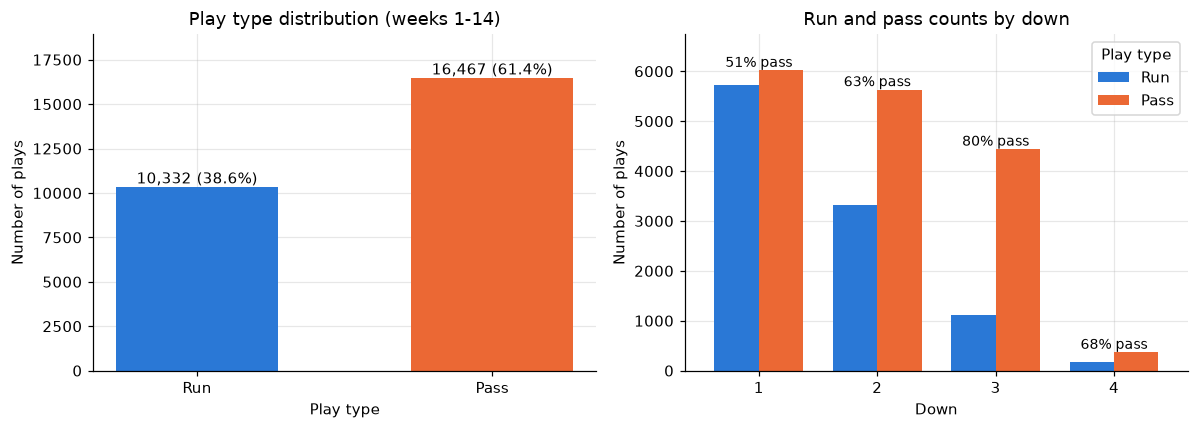

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

counts = eda["is_pass"].map({0: "Run", 1: "Pass"}).value_counts().reindex(["Run", "Pass"])
axes[0].bar(counts.index, counts.values, color=[RUN_COLOR, PASS_COLOR], width=0.55)
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,} ({v / counts.sum():.1%})", ha="center", va="bottom")
axes[0].set(title="Play type distribution (weeks 1-14)", xlabel="Play type", ylabel="Number of plays",
            ylim=(0, counts.max() * 1.15))

by_down = pd.crosstab(eda["down"].astype(int), eda["is_pass"]).rename(columns={0: "Run", 1: "Pass"})
by_down.plot.bar(ax=axes[1], color=[RUN_COLOR, PASS_COLOR], rot=0, width=0.75)
for i, (_, row) in enumerate(by_down.iterrows()):
    axes[1].text(i, row.max(), f"{row['Pass'] / row.sum():.0%} pass", ha="center", va="bottom", fontsize=9)
axes[1].set(title="Run and pass counts by down", xlabel="Down", ylabel="Number of plays",
            ylim=(0, by_down.values.max() * 1.12))
axes[1].legend(title="Play type")
plt.tight_layout()
plt.show()

**Takeaway.** 61.4% of training plays are passes, so always guessing "pass" is right 61% of the time; every model has to beat that. The pass rate rises with down: 51% on 1st, 63% on 2nd, 80% on 3rd. 4th downs are rare because most are punts or field goals (excluded).

### 3.2 Down and distance

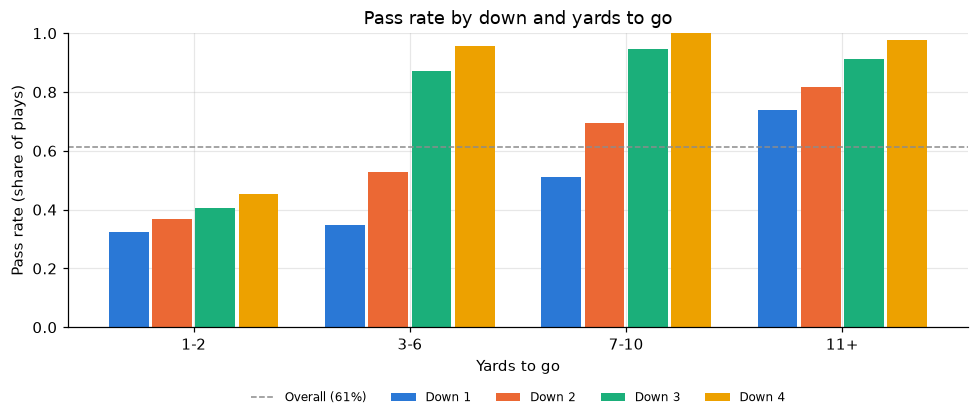

Plays per cell:
down         down 1  down 2  down 3  down 4
ydstogo_bin                                
1-2             163     941    1190     310
3-6             331    2586    1817     138
7-10          10811    4106    1542      57
11+             450    1315    1000      42


In [24]:
rate = eda.pivot_table(index="ydstogo_bin", columns="down", values="is_pass", aggfunc="mean", observed=True)
n_plays = eda.pivot_table(index="ydstogo_bin", columns="down", values="is_pass", aggfunc="size", observed=True)

fig, ax = plt.subplots(figsize=(9, 4))
width = 0.2
x = np.arange(len(rate.index))
for j, down in enumerate(rate.columns):
    ax.bar(x + (j - 1.5) * width, rate[down], width=width * 0.92, color=SERIES_COLORS[j], label=f"Down {int(down)}")
ax.axhline(overall_rate, color=NEUTRAL, ls="--", lw=1, label=f"Overall ({overall_rate:.0%})")
ax.set_xticks(x, rate.index)
ax.set(title="Pass rate by down and yards to go", xlabel="Yards to go", ylabel="Pass rate (share of plays)", ylim=(0, 1))
ax.legend(ncols=5, loc="upper center", bbox_to_anchor=(0.5, -0.18), fontsize=8, frameon=False)
plt.tight_layout()
plt.show()
print("Plays per cell:")
print(n_plays.rename(columns=lambda d: f"down {int(d)}").to_string())

**Takeaway.** Short yardage (1–2 yards) is run-heavy on every down (33–45% pass), while 3rd/4th down with 3+ yards to go is 87–100% pass. 1st-and-10, the most common situation, is close to 50/50, so it should be the hardest to predict. This motivates the `ydstogo_bin` and 3rd/4th-down flags in §4.

### 3.3 Formation and personnel

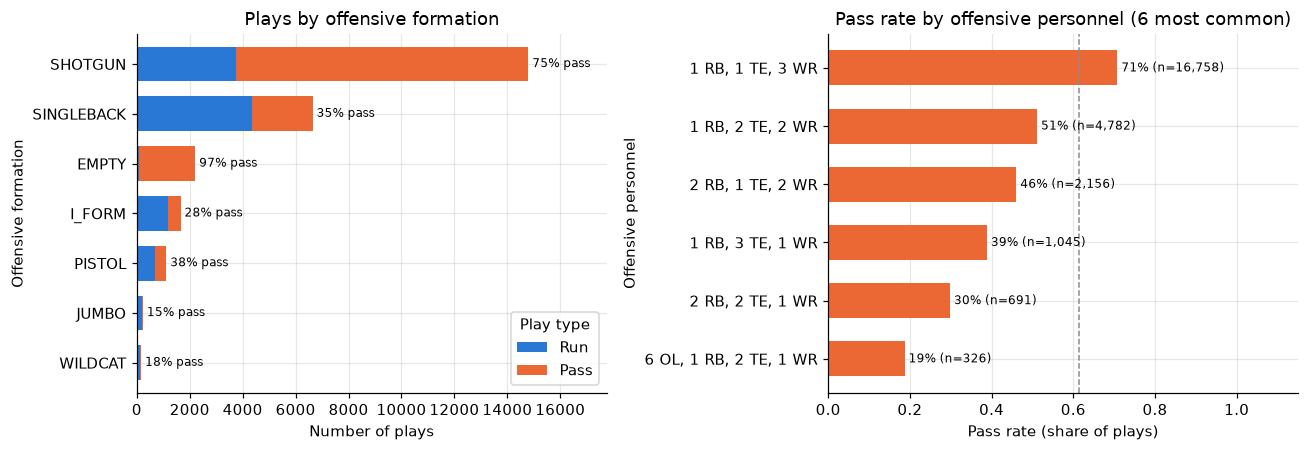

is_pass       run share  pass share
shotgun                            
shotgun           0.252       0.748
under center      0.671       0.329


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

form = pd.crosstab(eda["offense_formation"], eda["is_pass"]).rename(columns={0: "Run", 1: "Pass"})
form = form.loc[form.sum(axis=1).sort_values().index]
form.plot.barh(stacked=True, ax=axes[0], color=[RUN_COLOR, PASS_COLOR], width=0.7)
for i, (_, row) in enumerate(form.iterrows()):
    axes[0].text(row.sum(), i, f" {row['Pass'] / row.sum():.0%} pass", va="center", fontsize=8)
axes[0].set(title="Plays by offensive formation", xlabel="Number of plays", ylabel="Offensive formation",
            xlim=(0, form.sum(axis=1).max() * 1.2))
axes[0].legend(title="Play type", loc="lower right")

top_pers = eda["offense_personnel"].value_counts().head(6).index
pers = (eda[eda["offense_personnel"].isin(top_pers)].groupby("offense_personnel")["is_pass"]
        .agg(["mean", "size"]).sort_values("mean"))
axes[1].barh(pers.index, pers["mean"], color=PASS_COLOR, height=0.6)
for i, (m, n) in enumerate(zip(pers["mean"], pers["size"])):
    axes[1].text(m, i, f" {m:.0%} (n={n:,})", va="center", fontsize=8)
axes[1].axvline(overall_rate, color=NEUTRAL, ls="--", lw=1)
axes[1].set(title="Pass rate by offensive personnel (6 most common)", xlabel="Pass rate (share of plays)",
            ylabel="Offensive personnel", xlim=(0, 1.15))
plt.tight_layout()
plt.show()
print(pd.crosstab(eda["shotgun"].map({0: "under center", 1: "shotgun"}), eda["is_pass"], normalize="index")
      .rename(columns={0: "run share", 1: "pass share"}).round(3).to_string())

**Takeaway.** Formation is a strong signal: EMPTY is 97% pass and SHOTGUN 75%, while I_FORM, JUMBO and WILDCAT are 15–28% pass. Shotgun alone splits plays into 75% vs. 33% pass. More WRs means more passing (11 personnel: 71%); more TEs, RBs or linemen means more running (6 OL: 19%). This motivates parsing personnel into position counts.

### 3.4 Game situation: score, quarter and clock

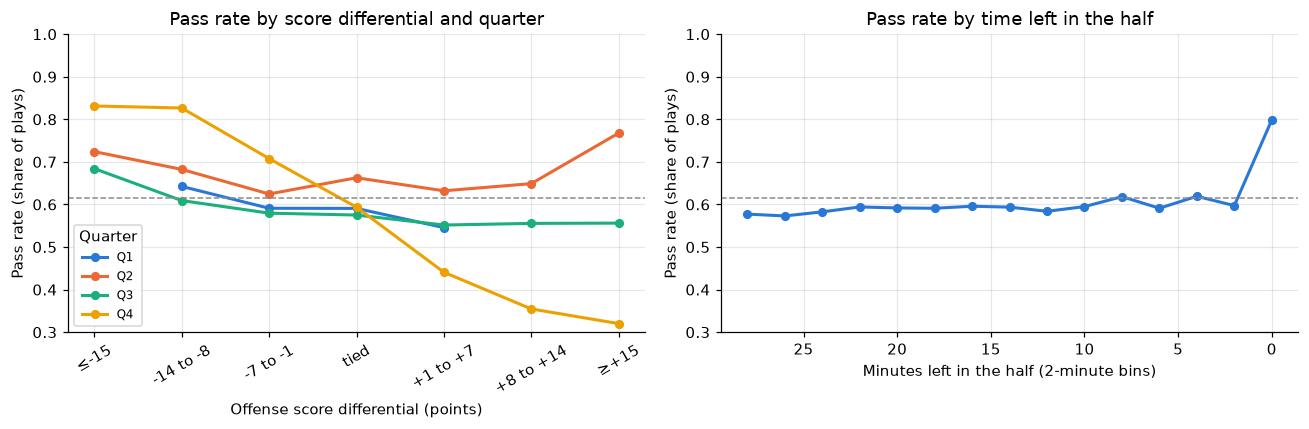

Hidden on the left plot (< 50 plays): [('Q1', '≤-15', 2), ('Q1', '+8 to +14', 40)]


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

score_bins = [-100, -15, -8, -1, 0, 7, 14, 100]   # (a, b] intervals match the labels
score_labels = ["≤-15", "-14 to -8", "-7 to -1", "tied", "+1 to +7", "+8 to +14", "≥+15"]
reg = eda[eda["qtr"] <= 4].copy()
reg["score_bin"] = pd.cut(reg["score_differential"], bins=score_bins, labels=score_labels)
by_score = reg.pivot_table(index="score_bin", columns="qtr", values="is_pass", aggfunc="mean", observed=True)
n_score = reg.pivot_table(index="score_bin", columns="qtr", values="is_pass", aggfunc="size", observed=True)
by_score = by_score.where(n_score >= 50)   # hide rates based on fewer than 50 plays
for j, q in enumerate(by_score.columns):
    axes[0].plot(range(len(by_score)), by_score[q], marker="o", ms=5, lw=2, color=SERIES_COLORS[j], label=f"Q{int(q)}")
axes[0].set_xticks(range(len(by_score)), by_score.index, rotation=30)
axes[0].axhline(overall_rate, color=NEUTRAL, ls="--", lw=1)
axes[0].set(title="Pass rate by score differential and quarter", xlabel="Offense score differential (points)",
            ylabel="Pass rate (share of plays)", ylim=(0.3, 1))
axes[0].legend(title="Quarter", fontsize=8)
hidden = [(f"Q{int(q)}", str(sb), int(n)) for sb, row in n_score.iterrows() for q, n in row.items() if n < 50]

eda["min_left_half"] = pd.cut(eda["half_seconds_remaining"] / 60, bins=range(0, 32, 2), right=False)
by_clock = eda.groupby("min_left_half", observed=True)["is_pass"].mean()
axes[1].plot([iv.left for iv in by_clock.index], by_clock.values, marker="o", ms=5, lw=2, color=SERIES_COLORS[0])
axes[1].axhline(overall_rate, color=NEUTRAL, ls="--", lw=1)
axes[1].invert_xaxis()
axes[1].set(title="Pass rate by time left in the half", xlabel="Minutes left in the half (2-minute bins)",
            ylabel="Pass rate (share of plays)", ylim=(0.3, 1))
plt.tight_layout()
plt.show()
print("Hidden on the left plot (< 50 plays):", hidden)

**Takeaway.** In quarters 1–3 the pass rate changes fairly little with the score (mostly 55–70%; Q2 with a 15+ point lead reaches 77%). In the 4th quarter it spreads out: trailing by 8 or more → 83% pass, leading by 15+ → 32% (running out the clock). The pass rate is flat (57–62%) until the last two minutes of a half, when it jumps to 80%. That is why we add `trailing_late` and `two_minute` flags.

### 3.5 Defenders in the box and weather

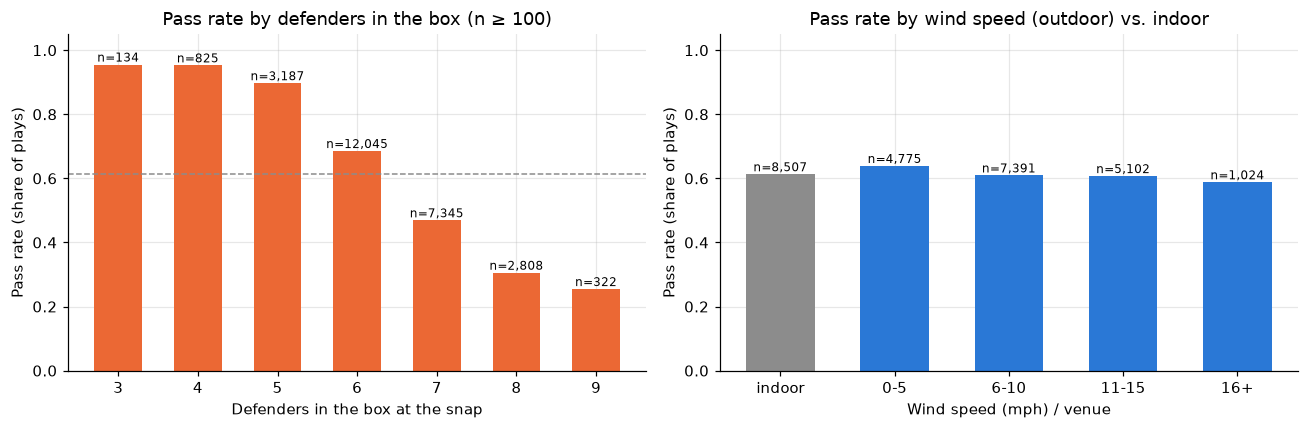

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

box = eda.groupby("defenders_in_box")["is_pass"].agg(["mean", "size"])
box = box[box["size"] >= 100]
axes[0].bar(box.index.astype(int).astype(str), box["mean"], color=PASS_COLOR, width=0.6)
for i, (m, n) in enumerate(zip(box["mean"], box["size"])):
    axes[0].text(i, m, f"n={n:,}", ha="center", va="bottom", fontsize=8)
axes[0].axhline(overall_rate, color=NEUTRAL, ls="--", lw=1)
axes[0].set(title="Pass rate by defenders in the box (n ≥ 100)", xlabel="Defenders in the box at the snap",
            ylabel="Pass rate (share of plays)", ylim=(0, 1.05))

venue = np.where(eda["is_indoor"] == 1, "indoor",
                 pd.cut(eda["wind"], bins=[-1, 5, 10, 15, 100], labels=["0-5", "6-10", "11-15", "16+"]).astype(str))
wind = eda.assign(venue=venue).groupby("venue")["is_pass"].agg(["mean", "size"]).reindex(["indoor", "0-5", "6-10", "11-15", "16+"])
axes[1].bar(wind.index, wind["mean"], color=[NEUTRAL] + [SERIES_COLORS[0]] * 4, width=0.6)
for i, (m, n) in enumerate(zip(wind["mean"], wind["size"])):
    axes[1].text(i, m, f"n={n:,}", ha="center", va="bottom", fontsize=8)
axes[1].set(title="Pass rate by wind speed (outdoor) vs. indoor", xlabel="Wind speed (mph) / venue",
            ylabel="Pass rate (share of plays)", ylim=(0, 1.05))
plt.tight_layout()
plt.show()

**Takeaway.** Defenders in the box is the strongest single numeric signal: 3–5 defenders → 90%+ pass, 8–9 → 25–30%. Part of this is the defense reacting to the offense's formation. It is measured at the snap, which fits our "available at the snap" setup, but it means the model partly reads the defense's own decision. Wind has only a small effect (64% pass when calm vs. 59% at 16+ mph).

### 3.6 Feature distributions and correlations
Missing values were handled in §2.4. Here: how key features differ between runs and passes, and which features are redundant.

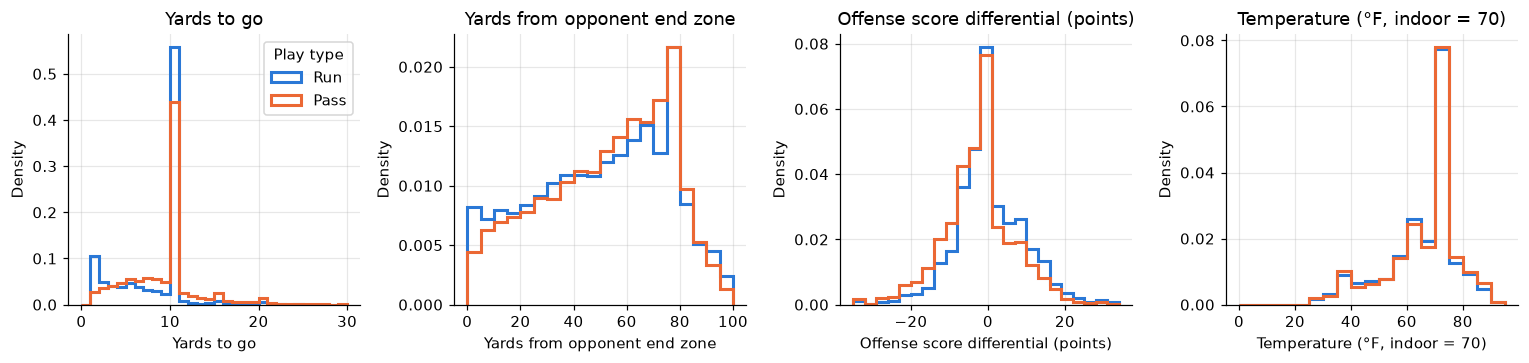

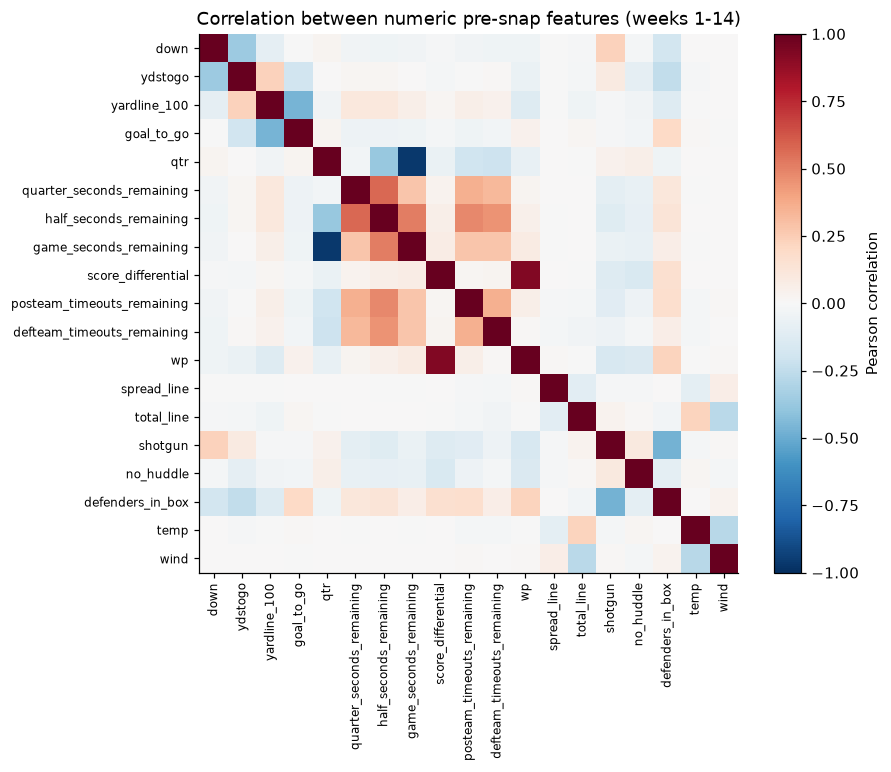

Most correlated feature pairs (|r| > 0.6):
qtr                 game_seconds_remaining   -0.96
score_differential  wp                        0.92


In [28]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
hist_cols = [("ydstogo", "Yards to go", np.arange(0, 31, 1)),
             ("yardline_100", "Yards from opponent end zone", np.arange(0, 101, 5)),
             ("score_differential", "Offense score differential (points)", np.arange(-35, 36, 3)),
             ("temp", "Temperature (°F, indoor = 70)", np.arange(0, 100, 5))]
for ax, (col, label, bins) in zip(axes, hist_cols):
    for val, name, color in [(0, "Run", RUN_COLOR), (1, "Pass", PASS_COLOR)]:
        ax.hist(eda.loc[eda["is_pass"] == val, col], bins=bins, density=True, histtype="step", lw=2, color=color, label=name)
    ax.set(title=label, xlabel=label, ylabel="Density")
axes[0].legend(title="Play type")
plt.tight_layout()
plt.show()

num_cols = [c for c in FEATURE_CANDIDATES if c in eda.select_dtypes("number").columns]
corr = eda[num_cols].corr()
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(num_cols)), num_cols, rotation=90, fontsize=8)
ax.set_yticks(range(len(num_cols)), num_cols, fontsize=8)
ax.grid(False)
fig.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Correlation between numeric pre-snap features (weeks 1-14)")
plt.tight_layout()
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print("Most correlated feature pairs (|r| > 0.6):")
print(pairs[pairs.abs() > 0.6].sort_values(key=abs, ascending=False).round(2).to_string())

**Takeaway.** The spike at 10 yards to go is 1st-and-10. Runs are more common at 1–2 yards to go and near the goal line. Two pairs are almost redundant: `qtr` vs. `game_seconds_remaining` (r = −0.96) and `score_differential` vs. `wp` (r = 0.92). Correlation matters when reading feature importance (§7.4), and the `wp` overlap is one reason we test it separately.

## §4 Feature engineering
New features are built only from whitelisted columns, and each has a football reason:

| Group | Features | Why |
|---|---|---|
| Personnel counts | `n_rb, n_te, n_wr, n_ol`, `n_dl, n_lb, n_db`, `box_minus_blockers` | 64 raw groupings become a few counts; extra WR/DB = passing look, extra OL/TE = running look |
| Situation | `ydstogo_bin` (binned), `red_zone`, `third_fourth_short`, `third_fourth_long`, `two_minute`, `trailing_late`, `posteam_spread`, `is_home` | Common coaching patterns, written as simple flags |
| Weather | `is_rain` (`is_snow` built but not used, see 4.5) | From the pre-game weather text, outdoor games only |
| Sequence / tendency | `prev_play`, `drive_play_number`, `team_prior_pass_rate` | Defenses track these too; built only from earlier plays / earlier weeks |

`data` is the cleaned table sorted into true game order (`game_id`, `order_sequence`).

In [29]:
data = clean.sort_values(["game_id", "order_sequence"]).reset_index(drop=True)

### 4.1 Personnel strings → position counts
Strings look like `"1 RB, 1 TE, 3 WR"`. Offensive linemen are only listed when there are more than five (`"6 OL, ..."`), so a missing OL count means 5. A few strings are irregular (two QBs, a defender on offense); we count the positions we care about and ignore the rest.

In [30]:
POSITIONS = ["QB", "RB", "TE", "WR", "OL", "DL", "LB", "DB"]

def parse_personnel(text: str) -> dict:
    counts = dict.fromkeys(POSITIONS, 0)
    for number, pos in re.findall(r"(\d+)\s*(QB|RB|TE|WR|OL|DL|LB|DB)", text):
        counts[pos] += int(number)
    return counts

off = pd.DataFrame([parse_personnel(s) for s in data["offense_personnel"]], index=data.index)
dfn = pd.DataFrame([parse_personnel(s) for s in data["defense_personnel"]], index=data.index)

data["n_rb"], data["n_te"], data["n_wr"] = off["RB"], off["TE"], off["WR"]
data["n_ol"] = off["OL"].replace(0, 5)            # OL only listed when > 5
data["n_dl"], data["n_lb"], data["n_db"] = dfn["DL"], dfn["LB"], dfn["DB"]
# defenders in the box minus the offense's in-line blockers (OL + TE): a light box invites the run
data["box_minus_blockers"] = data["defenders_in_box"] - (data["n_ol"] + data["n_te"])

assert (off[["RB", "TE", "WR"]].sum(axis=1) > 0).all() and (dfn[["DL", "LB", "DB"]].sum(axis=1) > 0).all()
print("offense skill players (RB+TE+WR):", (off["RB"] + off["TE"] + off["WR"]).value_counts().to_dict())
print("defense players (DL+LB+DB):     ", (dfn["DL"] + dfn["LB"] + dfn["DB"]).value_counts().to_dict())
data[["offense_personnel", "n_rb", "n_te", "n_wr", "n_ol", "defense_personnel", "n_dl", "n_lb", "n_db",
      "defenders_in_box", "box_minus_blockers"]].drop_duplicates("offense_personnel").head(5)

offense skill players (RB+TE+WR): {5: 35249, 4: 1165, 6: 87, 3: 32, 2: 6}
defense players (DL+LB+DB):      {11: 36489, 10: 36, 12: 14}


,offense_personnel,n_rb,n_te,n_wr,n_ol,defense_personnel,n_dl,n_lb,n_db,defenders_in_box,box_minus_blockers
0,"1 RB, 2 TE, 2 WR",1,2,2,5,"3 DL, 4 LB, 4 DB",3,4,4,7.0,0.0
4,"2 RB, 1 TE, 2 WR",2,1,2,5,"4 DL, 3 LB, 4 DB",4,3,4,7.0,1.0
7,"2 RB, 2 TE, 1 WR",2,2,1,5,"4 DL, 3 LB, 4 DB",4,3,4,7.0,0.0
8,"0 RB, 2 TE, 3 WR",0,2,3,5,"3 DL, 3 LB, 5 DB",3,3,5,5.0,-2.0
11,"1 RB, 1 TE, 3 WR",1,1,3,5,"2 DL, 3 LB, 6 DB",2,3,6,6.0,0.0


### 4.2 Situation flags, binning and offense-relative spread
`spread_line` is the **home** team's expected margin (positive = home favored). That means the same number means opposite things depending on who has the ball, so we replace it with `posteam_spread` (positive = offense favored) and check the sign: favored offenses should usually be the team that's ahead.

In [31]:
data["ydstogo_bin"] = pd.cut(data["ydstogo"], bins=YTG_BINS, labels=YTG_LABELS).astype(str)
data["red_zone"] = (data["yardline_100"] <= 20).astype(int)
data["third_fourth_short"] = ((data["down"] >= 3) & (data["ydstogo"] <= 2)).astype(int)
data["third_fourth_long"] = ((data["down"] >= 3) & (data["ydstogo"] >= 7)).astype(int)
data["two_minute"] = (data["half_seconds_remaining"] <= 120).astype(int)
data["trailing_late"] = ((data["score_differential"] < 0) & (data["game_seconds_remaining"] <= 900)).astype(int)

data["is_home"] = (data["posteam_type"] == "home").astype(int)
data["posteam_spread"] = np.where(data["is_home"] == 1, data["spread_line"], -data["spread_line"])

# sign check: favored offenses should tend to be ahead, so posteam_spread should correlate positively with the score
r_new = np.corrcoef(data["posteam_spread"], data["score_differential"])[0, 1]
r_raw = np.corrcoef(data["spread_line"], data["score_differential"])[0, 1]
print(f"corr with offense score differential: posteam_spread {r_new:.2f} | raw home-team spread_line {r_raw:.2f}")
assert r_new > 0.2, "posteam_spread has the wrong sign"

print(data[["red_zone", "third_fourth_short", "third_fourth_long", "two_minute", "trailing_late"]].mean().round(3).to_string())

corr with offense score differential: posteam_spread 0.31 | raw home-team spread_line 0.00
red_zone              0.147
third_fourth_short    0.056
third_fourth_long     0.099
two_minute            0.119
trailing_late         0.153


### 4.3 Weather flags
The `weather` text is a pre-game description, so it is known before every snap, but it describes the game, not each play. We only set the flags for outdoor/open-roof games: some dome games have text like "Rain" describing the weather outside.

In [32]:
weather_lc = data["weather"].str.lower()
outdoor = data["is_indoor"] == 0
data["is_rain"] = (outdoor & weather_lc.str.contains("rain|shower")).astype(int)
data["is_snow"] = (outdoor & weather_lc.str.contains("snow")).astype(int)
print(f"rain plays: {data['is_rain'].sum():,} in {data.loc[data['is_rain'] == 1, 'game_id'].nunique()} games | "
      f"snow plays: {data['is_snow'].sum():,} in {data.loc[data['is_snow'] == 1, 'game_id'].nunique()} games")

rain plays: 2,201 in 17 games | snow plays: 134 in 1 games


### 4.4 Sequence and team-tendency features
- `prev_play`: was the previous play **in the same drive** a pass, a run, or is this the first play (`none`)? Plays are sorted by `order_sequence` and shifted by one, so only earlier plays are used.
- `drive_play_number`: 1 for the first play of a drive, 2 for the next, and so on.
- `team_prior_pass_rate`: the offense's pass rate in **earlier weeks only**. It is missing in week 1 and filled by the Pipeline's median imputer.

In [33]:
drive = data.groupby(["game_id", "fixed_drive"])
data["drive_play_number"] = drive.cumcount() + 1
data["prev_play"] = drive["is_pass"].shift(1).map({1: "pass", 0: "run"}).fillna("none")
assert ((data["drive_play_number"] == 1) == (data["prev_play"] == "none")).all()

assert data.groupby(["posteam", "week"])["game_id"].nunique().max() == 1, "a team plays at most one game per week"

def team_prior_pass_rate(frame: pd.DataFrame) -> np.ndarray:
    """Each play's offense pass rate over earlier weeks of `frame` only (NaN if no earlier week)."""
    team_week = (frame.groupby(["posteam", "week"])["is_pass"].agg(passes="sum", plays="count")
                 .reset_index().sort_values(["posteam", "week"]))
    by_team = team_week.groupby("posteam")
    # cumulative totals minus the current week = totals over earlier weeks only
    team_week["rate"] = ((by_team["passes"].cumsum() - team_week["passes"])
                         / (by_team["plays"].cumsum() - team_week["plays"]))
    return frame[["posteam", "week"]].merge(team_week, on=["posteam", "week"], how="left")["rate"].to_numpy()

data["team_prior_pass_rate"] = team_prior_pass_rate(data)

# spot-check the chronology on one team-week against a direct computation
chk = data[(data["posteam"] == "KC") & (data["week"] == 10)]["team_prior_pass_rate"].iloc[0]
direct = data[(data["posteam"] == "KC") & (data["week"] < 10)]["is_pass"].mean()
assert np.isclose(chk, direct), (chk, direct)
assert data.loc[data["week"] == 1, "team_prior_pass_rate"].isna().all()
print(f"KC week 10 prior pass rate {chk:.3f} == direct mean over weeks 1-9 {direct:.3f}")
print("prev_play counts:", data["prev_play"].value_counts().to_dict())

KC week 10 prior pass rate 0.707 == direct mean over weeks 1-9 0.707
prev_play counts: {'pass': 17501, 'run': 13062, 'none': 5976}


### 4.5 Final feature lists
Three nested feature sets, so §6.6 can measure what each kind of information adds:
- **A: game situation** (play-by-play only): down, distance, field position, clock, score, timeouts, home/away, game total, weather.
- **B: A + alignment:** shotgun, no-huddle, formation, raw personnel groupings, defenders in the box.
- **C: B + engineered features** from §4.1–4.4. This is our main feature set.

Left out on purpose: raw `spread_line` (replaced by `posteam_spread`), `posteam_type`, `roof` and the `weather` text (replaced by flags), `surface` (no clear football reason), team names (the model would memorize teams; `team_prior_pass_rate` captures tendency) and `wp` (nflverse's own model output, tested separately in §6.6).

In [34]:
SITUATION_NUM = ["down", "ydstogo", "yardline_100", "goal_to_go", "qtr", "quarter_seconds_remaining",
                 "half_seconds_remaining", "game_seconds_remaining", "score_differential",
                 "posteam_timeouts_remaining", "defteam_timeouts_remaining", "is_home", "total_line",
                 "temp", "wind", "is_indoor"]
ALIGN_NUM = ["shotgun", "no_huddle", "defenders_in_box"]
ALIGN_CAT = ["offense_formation", "offense_personnel", "defense_personnel"]
ENGINEERED_NUM = ["n_rb", "n_te", "n_wr", "n_ol", "n_dl", "n_lb", "n_db", "box_minus_blockers",
                  "red_zone", "third_fourth_short", "third_fourth_long", "two_minute", "trailing_late",
                  "posteam_spread", "is_rain", "drive_play_number", "team_prior_pass_rate"]
# is_snow is left out: the only snow game is in the test weeks, so the flag is all zeros in training
ENGINEERED_CAT = ["ydstogo_bin", "prev_play"]

FEATURE_SETS = {
    "A: game situation":        (SITUATION_NUM, []),
    "B: + formation/personnel": (SITUATION_NUM + ALIGN_NUM, ALIGN_CAT),
    "C: + engineered (final)":  (SITUATION_NUM + ALIGN_NUM + ENGINEERED_NUM, ALIGN_CAT + ENGINEERED_CAT),
}
NUM_FEATURES, CAT_FEATURES = FEATURE_SETS["C: + engineered (final)"]
FEATURES = NUM_FEATURES + CAT_FEATURES

# leakage guards: no IDs, auxiliary/benchmark columns, or the target; every input is a whitelisted column or built from them
FORBIDDEN = set(ID_COLS + AUX_COLS + BENCHMARK_COLS + [TARGET, "yards_gained", "pass", "rush", "play_type"])
assert FORBIDDEN.isdisjoint(FEATURES)
assert set(FEATURES) <= set(FEATURE_CANDIDATES) | set(ENGINEERED_NUM + ENGINEERED_CAT + ["is_home", "is_indoor"])
assert len(FEATURES) == len(set(FEATURES))
assert data[NUM_FEATURES].drop(columns="team_prior_pass_rate").notna().all().all()
print(f"{len(NUM_FEATURES)} numeric + {len(CAT_FEATURES)} categorical = {len(FEATURES)} input columns (set C)")

36 numeric + 5 categorical = 41 input columns (set C)


## §5 Train/test split and cross-validation

**Split.** Train on weeks 1–14; test on weeks 15–18 + playoffs. This mimics real use (predicting future games from past ones), and every game is entirely on one side. The test set is used **once**, in §7.

**Cross-validation (CV): forward-chaining by week.** Inside weeks 1–14 we use 4 folds. Each fold validates on two weeks (7–8, 9–10, 11–12, 13–14) and trains only on the weeks **before** them. Whole weeks stay together, so no game is split between training and validation.

*Why not regular `GroupKFold`?* `team_prior_pass_rate` uses earlier weeks' results. With non-chronological folds, a training play from week 10 could use results from a week-6 game in the validation fold, leaking validation labels into training. The check below measures this.

In [35]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, GroupKFold, RandomizedSearchCV, cross_validate,
                                     validation_curve)   # GroupKFold only for the comparison check below
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree

train = data[data["week"] <= TRAIN_MAX_WEEK].reset_index(drop=True)
test = data[data["week"] > TRAIN_MAX_WEEK].reset_index(drop=True)
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

assert set(train["game_id"]).isdisjoint(test["game_id"]), "a game appears in both train and test"
assert len(train) + len(test) == len(data)
assert not data.duplicated(["game_id", "play_id"]).any()
assert set(y_train.unique()) == {0, 1} and set(y_test.unique()) == {0, 1}
assert train["is_snow"].sum() == 0  # why is_snow is not a feature (see 4.5)

split = pd.DataFrame({
    "weeks": [f"1-{TRAIN_MAX_WEEK}", f"{TRAIN_MAX_WEEK + 1}-18 + playoffs"],
    "games": [train["game_id"].nunique(), test["game_id"].nunique()],
    "plays": [len(train), len(test)],
    "pass rate": [y_train.mean().round(3), y_test.mean().round(3)],
}, index=["train", "test"])
display(split)

VAL_BLOCKS = [(7, 8), (9, 10), (11, 12), (13, 14)]

def week_splits(weeks: pd.Series) -> list:
    """Forward-chaining CV: for each 2-week validation block, train on all earlier weeks."""
    w = weeks.to_numpy()
    return [(np.where(w < lo)[0], np.where((w >= lo) & (w <= hi))[0]) for lo, hi in VAL_BLOCKS]

cv = week_splits(train["week"])
fold_info = []
for (tr_idx, va_idx), (lo, hi) in zip(cv, VAL_BLOCKS):
    tr_rows, va_rows = train.iloc[tr_idx], train.iloc[va_idx]
    assert tr_rows["week"].max() < va_rows["week"].min()                # strictly chronological
    assert set(tr_rows["game_id"]).isdisjoint(va_rows["game_id"])      # whole games on one side
    # training features use training labels only: recomputing from training rows alone gives the same values
    assert np.allclose(team_prior_pass_rate(tr_rows), tr_rows["team_prior_pass_rate"], equal_nan=True)
    fold_info.append({"train weeks": f"1-{lo - 1}", "validation weeks": f"{lo}-{hi}",
                      "train plays": len(tr_idx), "validation plays": len(va_idx)})
display(pd.DataFrame(fold_info))

,weeks,games,plays,pass rate
train,1-14,208,26799,0.614
test,15-18 + playoffs,76,9740,0.599


,train weeks,validation weeks,train plays,validation plays
0,1-6,7-8,12130,3693
1,1-8,9-10,15823,3495
2,1-10,11-12,19318,3848
3,1-12,13-14,23166,3633


**Check: how much would `GroupKFold` leak?** For each `GroupKFold` split, we count training plays whose `team_prior_pass_rate` includes a game from that split's validation fold.

In [36]:
leaky, total = 0, 0
for tr_idx, va_idx in GroupKFold(n_splits=5).split(X_train, y_train, train["game_id"]):
    val_weeks = train.iloc[va_idx].groupby("posteam")["week"].min()     # earliest validation game per team
    tr_rows = train.iloc[tr_idx]
    leaky += (tr_rows["week"] > tr_rows["posteam"].map(val_weeks)).sum()
    total += len(tr_idx)
print(f"GroupKFold: {leaky / total:.1%} of training-fold plays carry validation-fold labels in team_prior_pass_rate")
print("Forward-chaining: 0% (asserted above)")

GroupKFold: 62.6% of training-fold plays carry validation-fold labels in team_prior_pass_rate
Forward-chaining: 0% (asserted above)


### 5.1 Preprocessing pipeline
Every model goes inside the same `Pipeline`, so preprocessing is learned from the training folds only:
- **Numeric columns:** median imputer (only `team_prior_pass_rate` has gaps, in week 1).
- **Categorical columns:** one-hot encoding; groupings seen on < 0.5% of training plays are pooled into one "infrequent" column, and unseen categories go there too.
- **No scaling:** all three models are tree-based, and tree splits don't change when a feature is rescaled.

In [37]:
def make_pipeline(model, num_cols=NUM_FEATURES, cat_cols=CAT_FEATURES):
    prep = ColumnTransformer(
        [("num", SimpleImputer(strategy="median"), num_cols),
         ("cat", OneHotEncoder(min_frequency=0.005, handle_unknown="infrequent_if_exist", sparse_output=False), cat_cols)],
        verbose_feature_names_out=False)
    return Pipeline([("prep", prep), ("model", model)])

prep_check = make_pipeline(DummyClassifier())["prep"].fit(X_train)
print(f"{len(FEATURES)} input columns -> {len(prep_check.get_feature_names_out())} model columns after one-hot encoding")

41 input columns -> 72 model columns after one-hot encoding


### 5.2 Quick signal check of the engineered features
Univariate ROC-AUC of each engineered feature on the training weeks (same function as §2.3): a check that each carries some signal and none is suspiciously perfect. We don't drop features based on it.

In [38]:
fe_scan = univariate_auc(train[ENGINEERED_NUM], y_train).reset_index(drop=True)
assert (fe_scan["auc"] < LEAK_THRESHOLD).all()
fe_scan.round(3)

,column,via,auc
0,n_db,value,0.649
1,box_minus_blockers,value,0.644
2,n_wr,value,0.637
3,n_te,value,0.592
4,n_dl,value,0.580
5,third_fourth_long,value,0.567
6,trailing_late,value,0.553
7,n_rb,value,0.551
8,drive_play_number,value,0.549
9,team_prior_pass_rate,value,0.542


**Takeaway.** The personnel counts carry real signal on their own (`n_db` 0.65, `box_minus_blockers` 0.64, `n_wr` 0.64), and nothing is near the 0.90 leakage threshold. `posteam_spread` and `is_rain` are ~0.50 alone. That doesn't make them useless (trees can use them in interactions), and §6.6/§7.4 check whether they help.

### 5.3 Evaluation protocol
- **Positive class = pass (1).** Precision, recall and F1 refer to passes unless labeled "run".
- **Main metric: ROC-AUC.** It measures how well the model ranks passes above runs, regardless of the cutoff, so always predicting the majority class scores only 0.5. We also track accuracy and F1.
- **CV scores** (mean of the 4 folds) drive every decision. **Test scores** are computed once, in §7, for the final models only.

In [39]:
SCORING = {"roc_auc": "roc_auc", "accuracy": "accuracy", "f1": "f1"}

def cv_summary(pipe, X=X_train, y=y_train, splits=cv) -> dict:
    """Mean forward-chaining CV scores on the training weeks (plus training-fold AUC to gauge overfitting)."""
    res = cross_validate(pipe, X, y, cv=splits, scoring=SCORING, return_train_score=True, n_jobs=-1)
    return {"CV ROC-AUC": res["test_roc_auc"].mean(), "CV AUC std": res["test_roc_auc"].std(),
            "CV accuracy": res["test_accuracy"].mean(), "CV F1": res["test_f1"].mean(),
            "train-fold AUC": res["train_roc_auc"].mean()}

def search_summary(search) -> dict:
    """Same metrics for the best configuration of a fitted Grid/RandomizedSearchCV."""
    r, i = search.cv_results_, search.best_index_
    return {"CV ROC-AUC": r["mean_test_roc_auc"][i], "CV AUC std": r["std_test_roc_auc"][i],
            "CV accuracy": r["mean_test_accuracy"][i], "CV F1": r["mean_test_f1"][i],
            "train-fold AUC": r["mean_train_roc_auc"][i]}

def top_configs(search, n=5) -> pd.DataFrame:
    r = pd.DataFrame(search.cv_results_)
    cols = [c for c in r.columns if c.startswith("param_")] + ["mean_test_roc_auc", "mean_train_roc_auc", "mean_test_accuracy"]
    out = r.sort_values("rank_test_roc_auc")[cols].head(n)
    return out.rename(columns=lambda c: c.replace("param_model__", "")).round(4)

cv_table = {}

## §6 Modeling

### 6.1 Baselines
**Majority class.** `DummyClassifier(strategy="most_frequent")` always predicts the most common play type in the training data. A useful model has to beat it.

**Shotgun rule.** Predict pass whenever the QB is in shotgun. It needs no training, so we just score it on the same validation weeks.

In [40]:
majority = make_pipeline(DummyClassifier(strategy="most_frequent"))
majority.fit(X_train, y_train)
majority_class = majority["model"].classes_[np.argmax(majority["model"].class_prior_)]
print(f"Training class distribution: {y_train.value_counts(normalize=True).rename({1: 'pass', 0: 'run'}).round(3).to_dict()}")
print(f"Majority class: {'pass' if majority_class == 1 else 'run'} ({majority_class})")

cv_table["Majority baseline"] = cv_summary(majority)
# the shotgun rule needs no fitting: score it on the same validation blocks
shot_auc = [roc_auc_score(y_train.iloc[va], X_train["shotgun"].iloc[va]) for _, va in cv]
shot_acc = [accuracy_score(y_train.iloc[va], X_train["shotgun"].iloc[va]) for _, va in cv]
shot_f1 = [f1_score(y_train.iloc[va], X_train["shotgun"].iloc[va]) for _, va in cv]
cv_table["Shotgun rule"] = {"CV ROC-AUC": np.mean(shot_auc), "CV AUC std": np.std(shot_auc),
                            "CV accuracy": np.mean(shot_acc), "CV F1": np.mean(shot_f1), "train-fold AUC": np.nan}
pd.DataFrame(cv_table).T.round(4)

Training class distribution: {'pass': 0.614, 'run': 0.386}
Majority class: pass (1)


,CV ROC-AUC,CV AUC std,CV accuracy,CV F1,train-fold AUC
Majority baseline,0.5000,0.0000,0.6066,0.7551,0.5
Shotgun rule,0.6876,0.0015,0.7182,0.7816,NaN


**Takeaway.** The majority class is **pass**. On the validation blocks the majority baseline scores 60.7% accuracy and ROC-AUC 0.50 (it gives every play the same score). Its pass-F1 (0.755) looks high only because predicting "pass" everywhere gives perfect pass recall; it never identifies a run. The one-feature shotgun rule reaches 71.8% accuracy (AUC 0.69), a tougher second baseline.

### 6.2 Decision tree
A decision tree repeatedly splits the plays on the feature and threshold that most reduce impurity (Gini or entropy). It was our originally proposed model and is easy to interpret, but it overfits if it grows too deep.

**Untuned (sklearn defaults, unlimited depth):**

In [41]:
cv_table["Decision tree (default)"] = cv_summary(make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)))
pd.DataFrame(cv_table).T.loc[["Decision tree (default)"]].round(4)

,CV ROC-AUC,CV AUC std,CV accuracy,CV F1,train-fold AUC
Decision tree (default),0.6505,0.0084,0.6648,0.7219,1.0


**Depth vs. overfitting.** We vary only `max_depth` and compare training-fold AUC with validation-fold AUC.

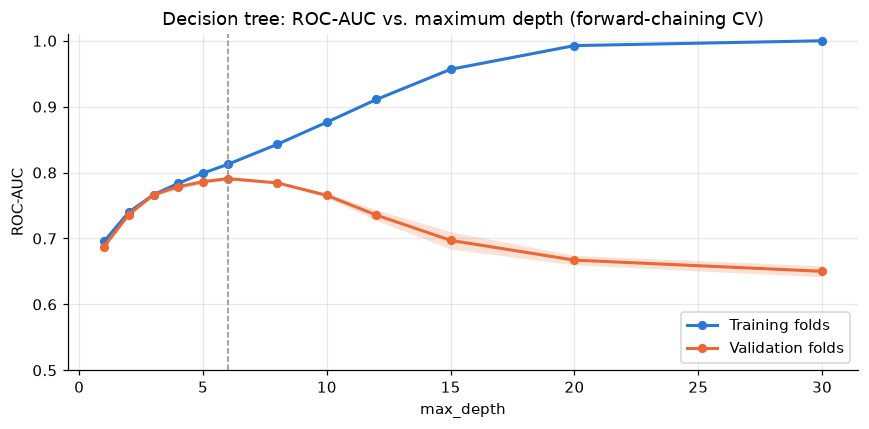

best validation AUC 0.7909 at max_depth=6


In [42]:
depths = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 30]
train_auc, val_auc = validation_curve(
    make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)), X_train, y_train,
    param_name="model__max_depth", param_range=depths, cv=cv, scoring="roc_auc", n_jobs=-1)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(depths, train_auc.mean(axis=1), marker="o", ms=5, lw=2, color=SERIES_COLORS[0], label="Training folds")
ax.plot(depths, val_auc.mean(axis=1), marker="o", ms=5, lw=2, color=SERIES_COLORS[1], label="Validation folds")
ax.fill_between(depths, val_auc.mean(axis=1) - val_auc.std(axis=1), val_auc.mean(axis=1) + val_auc.std(axis=1),
                color=SERIES_COLORS[1], alpha=0.2, lw=0)
best_depth = depths[int(np.argmax(val_auc.mean(axis=1)))]
ax.axvline(best_depth, color=NEUTRAL, ls="--", lw=1)
ax.set(title="Decision tree: ROC-AUC vs. maximum depth (forward-chaining CV)", xlabel="max_depth",
       ylabel="ROC-AUC", ylim=(0.5, 1.01))
ax.legend()
plt.tight_layout()
plt.show()
print(f"best validation AUC {val_auc.mean(axis=1).max():.4f} at max_depth={best_depth}")

**Takeaway.** This is the classic bias–variance picture. Shallow trees underfit (depth 1–3, both curves low). Validation AUC peaks at depth 6 (0.791); deeper trees keep raising the training AUC toward 1.0 while the validation AUC falls. The default unlimited-depth tree memorizes its training data (train AUC 1.00, CV AUC 0.65), which is worse than the shotgun rule.

**Grid search** over depth, leaf size, split size and impurity criterion (5 × 3 × 2 × 2 = 60 configurations × 4 folds):

In [43]:
dt_grid = {
    "model__max_depth": [4, 6, 8, 10, 12],
    "model__min_samples_leaf": [1, 25, 100],
    "model__min_samples_split": [2, 200],
    "model__criterion": ["gini", "entropy"],
}
dt_search = GridSearchCV(make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)), dt_grid,
                         scoring=SCORING, refit="roc_auc", cv=cv, n_jobs=-1, return_train_score=True)
dt_search.fit(X_train, y_train)
cv_table["Decision tree (tuned)"] = search_summary(dt_search)
print("best params:", dt_search.best_params_)
top_configs(dt_search)

best params: {'model__criterion': 'entropy', 'model__max_depth': 12, 'model__min_samples_leaf': 100, 'model__min_samples_split': 2}


,criterion,max_depth,min_samples_leaf,min_samples_split,mean_test_roc_auc,mean_train_roc_auc,mean_test_accuracy
59,entropy,12,100,200,0.8117,0.8311,0.7402
58,entropy,12,100,2,0.8117,0.8311,0.7402
53,entropy,10,100,200,0.8108,0.8253,0.7405
52,entropy,10,100,2,0.8108,0.8253,0.7405
57,entropy,12,25,200,0.8089,0.8352,0.7383


For interpretation, here is a depth-3 tree trained on the same data (not the tuned model, which is too deep to draw):

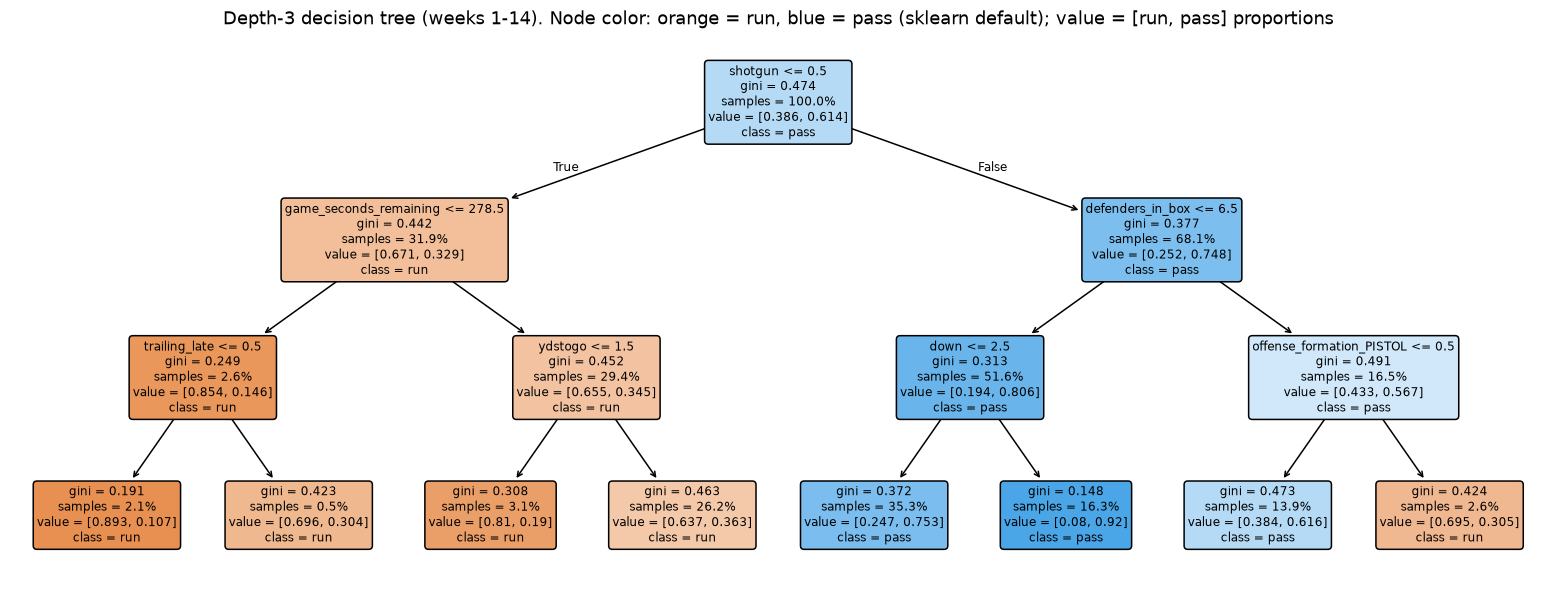

In [44]:
small_tree = make_pipeline(DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)).fit(X_train, y_train)
fig, ax = plt.subplots(figsize=(18, 6.5))
plot_tree(small_tree["model"], feature_names=small_tree["prep"].get_feature_names_out(), class_names=["run", "pass"],
          filled=True, impurity=True, proportion=True, rounded=True, fontsize=8, ax=ax)
ax.set_title("Depth-3 decision tree (weeks 1-14). Node color: orange = run, blue = pass (sklearn default); value = [run, pass] proportions")
plt.show()

**Takeaway.** The grid picks entropy, `max_depth=12` and `min_samples_leaf=100`. `min_samples_split` doesn't matter here: a leaf of 100 already forces every split to have ≥ 200 plays. With large leaves, a deeper tree still generalizes. CV AUC rises from 0.651 (default) to 0.812, and the train–CV gap stays small (0.83 vs. 0.81). The depth-3 tree is readable football: the first split is shotgun; under center, very late game and short yardage → run; in shotgun, ≤ 6 box defenders → pass, especially on 3rd/4th down.

### 6.3 Random forest
A random forest averages many deep trees. Each tree is trained on a bootstrap sample of the plays (**bagging**) and considers a random subset of features at each split. This makes the trees different from each other, and averaging them reduces variance (overfitting).

**Untuned (sklearn defaults: 100 trees, unlimited depth):**

In [45]:
cv_table["Random forest (default)"] = cv_summary(make_pipeline(RandomForestClassifier(random_state=RANDOM_STATE)))
pd.DataFrame(cv_table).T.loc[["Random forest (default)"]].round(4)

,CV ROC-AUC,CV AUC std,CV accuracy,CV F1,train-fold AUC
Random forest (default),0.8204,0.0046,0.7475,0.7935,1.0


**Randomized search:** 12 of the 192 combinations, sampled with a fixed seed (a full grid would take much longer).

In [46]:
rf_dist = {
    "model__n_estimators": [150, 300],
    "model__max_depth": [8, 12, 16, None],
    "model__min_samples_leaf": [1, 5, 20, 50],
    "model__max_features": ["sqrt", 0.25, 0.4],
    "model__class_weight": [None, "balanced"],
}
rf_search = RandomizedSearchCV(make_pipeline(RandomForestClassifier(random_state=RANDOM_STATE)), rf_dist, n_iter=12,
                               scoring=SCORING, refit="roc_auc", cv=cv, n_jobs=-1, return_train_score=True,
                               random_state=RANDOM_STATE)
rf_search.fit(X_train, y_train)
cv_table["Random forest (tuned)"] = search_summary(rf_search)
print("best params:", rf_search.best_params_)
top_configs(rf_search)

best params: {'model__n_estimators': 300, 'model__min_samples_leaf': 20, 'model__max_features': 0.4, 'model__max_depth': 16, 'model__class_weight': 'balanced'}


,n_estimators,min_samples_leaf,max_features,max_depth,class_weight,mean_test_roc_auc,mean_train_roc_auc,mean_test_accuracy
6,300,20,0.4,16,balanced,0.8265,0.8923,0.7380
0,150,5,0.4,12,NaN,0.8260,0.9156,0.7504
11,150,5,sqrt,16,balanced,0.8252,0.9257,0.7429
2,150,1,0.4,16,NaN,0.8251,0.9908,0.7517
3,300,50,0.4,None,balanced,0.8238,0.8583,0.7361


**Takeaway.** The default forest (unlimited depth) already reaches CV AUC 0.820 despite memorizing its training data (train AUC 1.0): averaging many overfit trees cancels much of their variance. Tuning adds +0.006. The best sampled setting (300 trees, depth 16, leaf 20, 40% of features, `class_weight="balanced"`) scores 0.8265, vs. 0.8260 for the best unweighted setting. Class weighting barely changes AUC, but it shifts scores toward "run". At the 0.5 threshold, CV accuracy is therefore lower (0.738 vs. 0.750 unweighted).

### 6.4 Boosting: AdaBoost
AdaBoost builds small trees **one after another**. After each tree, it gives more weight to the plays that tree got wrong, so the next tree focuses on them; the final prediction is a weighted vote. Bagging mainly reduces variance, boosting mainly reduces bias (underfitting).

**Untuned (sklearn defaults: 50 one-split trees, learning rate 1.0):**

In [47]:
cv_table["AdaBoost (default)"] = cv_summary(make_pipeline(AdaBoostClassifier(random_state=RANDOM_STATE)))
pd.DataFrame(cv_table).T.loc[["AdaBoost (default)"]].round(4)

,CV ROC-AUC,CV AUC std,CV accuracy,CV F1,train-fold AUC
AdaBoost (default),0.8066,0.0039,0.7384,0.7911,0.8088


**Grid search** over base-tree depth, number of trees and learning rate (3 × 2 × 3 = 18 configurations × 4 folds):

In [48]:
ada_grid = {
    "model__estimator__max_depth": [1, 2, 3],
    "model__n_estimators": [100, 300],
    "model__learning_rate": [0.1, 0.5, 1.0],
}
ada_search = GridSearchCV(
    make_pipeline(AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), random_state=RANDOM_STATE)),
    ada_grid, scoring=SCORING, refit="roc_auc", cv=cv, n_jobs=-1, return_train_score=True)
ada_search.fit(X_train, y_train)
cv_table["AdaBoost (tuned)"] = search_summary(ada_search)
print("best params:", ada_search.best_params_)
top_configs(ada_search)

best params: {'model__estimator__max_depth': 3, 'model__learning_rate': 0.5, 'model__n_estimators': 300}


,estimator__max_depth,learning_rate,n_estimators,mean_test_roc_auc,mean_train_roc_auc,mean_test_accuracy
15,3,0.5,300,0.8267,0.8383,0.7491
11,2,1.0,300,0.8250,0.8376,0.7498
14,3,0.5,100,0.8234,0.8316,0.7466
17,3,1.0,300,0.8233,0.8443,0.7468
9,2,0.5,300,0.8233,0.8299,0.7485


**Takeaway.** Default AdaBoost (50 stumps) underfits slightly (train AUC 0.81 ≈ CV 0.81). Deeper base trees (depth 3), more of them (300) and a smaller learning rate (0.5) raise CV AUC to 0.827 with only a small train–CV gap (0.84 vs. 0.83). Boosting mainly reduces bias, whereas the forest mainly reduces variance.

### 6.5 Tuning summary and model selection
All numbers are **cross-validation** scores on the training weeks. The model with the highest CV ROC-AUC becomes our final model.

In [49]:
cv_df = pd.DataFrame(cv_table).T
cv_df["AUC gain from tuning"] = np.nan
for name in ["Decision tree", "Random forest", "AdaBoost"]:
    cv_df.loc[f"{name} (tuned)", "AUC gain from tuning"] = (cv_df.loc[f"{name} (tuned)", "CV ROC-AUC"]
                                                           - cv_df.loc[f"{name} (default)", "CV ROC-AUC"])
display(cv_df.round(4))

searches = {"Decision tree": dt_search, "Random forest": rf_search, "AdaBoost": ada_search}
best_name = max(searches, key=lambda n: searches[n].best_score_)
best_search = searches[best_name]
print(f"Selected model (highest CV ROC-AUC): {best_name}  ->  {best_search.best_score_:.4f}")

,CV ROC-AUC,CV AUC std,CV accuracy,CV F1,train-fold AUC,AUC gain from tuning
Majority baseline,0.5000,0.0000,0.6066,0.7551,0.5000,NaN
Shotgun rule,0.6876,0.0015,0.7182,0.7816,NaN,NaN
Decision tree (default),0.6505,0.0084,0.6648,0.7219,1.0000,NaN
Decision tree (tuned),0.8117,0.0058,0.7402,0.7892,0.8311,0.1612
Random forest (default),0.8204,0.0046,0.7475,0.7935,1.0000,NaN
Random forest (tuned),0.8265,0.0039,0.7380,0.7634,0.8923,0.0061
AdaBoost (default),0.8066,0.0039,0.7384,0.7911,0.8088,NaN
AdaBoost (tuned),0.8267,0.0039,0.7491,0.7976,0.8383,0.0200


Selected model (highest CV ROC-AUC): AdaBoost  ->  0.8267


**Takeaway.** All three tuned models beat both baselines. AdaBoost has the highest CV AUC and is selected, but its lead over the random forest (0.0002) is tiny compared with the fold-to-fold variation (~0.004), so the two perform about the same. With an earlier, non-chronological CV the forest was ahead by a similar margin; we did not run a formal significance test. The single tree is about 0.015 lower. The selection rule is fixed and not revisited after seeing test results.

### 6.6 Did the extra data and feature engineering help? (feature-set ablation)
Same model (the selected one, with its tuned settings), same folds, different inputs:
- A → B: value of the **participation data** (formation, personnel, box count).
- B → C: value of our **engineered features**.
- Two variants: C **without** the sequence/tendency features, and C **plus** nflverse's `wp`.

These are CV scores only; feature sets are not compared on the test set. The settings were tuned on C, which slightly favors C.

In [50]:
from sklearn.base import clone

SEQ = ["drive_play_number", "team_prior_pass_rate"]
ablation_sets = dict(FEATURE_SETS)
ablation_sets["C without sequence/tendency"] = ([c for c in NUM_FEATURES if c not in SEQ],
                                                [c for c in CAT_FEATURES if c != "prev_play"])
ablation_sets["C + wp"] = (NUM_FEATURES + ["wp"], CAT_FEATURES)

best_model = best_search.best_estimator_["model"]
ablation = {}
for name, (num, cat) in ablation_sets.items():
    pipe = make_pipeline(clone(best_model), num, cat)
    ablation[name] = {"n input columns": len(num) + len(cat), **cv_summary(pipe, X=train[num + cat])}
ablation_df = pd.DataFrame(ablation).T
ablation_df["Δ CV AUC vs. A"] = ablation_df["CV ROC-AUC"] - ablation_df.loc["A: game situation", "CV ROC-AUC"]
ablation_df.round(4)

,n input columns,CV ROC-AUC,CV AUC std,CV accuracy,CV F1,train-fold AUC,Δ CV AUC vs. A
A: game situation,16.0,0.7710,0.0043,0.6984,0.7552,0.7868,0.0000
B: + formation/personnel,22.0,0.8213,0.0033,0.7473,0.7964,0.8323,0.0503
C: + engineered (final),41.0,0.8267,0.0039,0.7491,0.7976,0.8383,0.0557
C without sequence/tendency,38.0,0.8238,0.0046,0.7473,0.7966,0.8344,0.0528
C + wp,42.0,0.8270,0.0047,0.7489,0.7976,0.8378,0.0560


**Takeaway (CV, training weeks only).**
- **Merging the participation data is the big gain:** A → B adds +0.050 AUC and +4.9 points of accuracy. Formation, personnel and box count carry information the play-by-play situation alone does not.
- **Engineered features add a little:** B → C adds +0.005 AUC, about one fold standard deviation, so the evidence of a benefit is weak. Removing the sequence/tendency features costs 0.003.
- **`wp` adds nothing measurable** (+0.0003), consistent with its 0.92 correlation with score differential. We leave it out to keep the model independent of nflverse's own models.

## §7 Results and analysis

### 7.1 Final test-set evaluation
Each tuned model is refit on all of weeks 1–14 and evaluated **once** on weeks 15–18 + playoffs. Positive class = pass; label-based metrics use a 0.5 cutoff, and ROC-AUC uses the predicted scores.

In [51]:
final_models = {"Decision tree": dt_search.best_estimator_, "Random forest": rf_search.best_estimator_,
                "AdaBoost": ada_search.best_estimator_}

test_proba = {"Majority baseline": majority.predict_proba(X_test)[:, 1],
              "Shotgun rule": X_test["shotgun"].to_numpy(dtype=float)}
for name, model in final_models.items():
    test_proba[name] = model.predict_proba(X_test)[:, 1]
for name, p in test_proba.items():
    assert p.shape == (len(X_test),) and np.all((p >= 0) & (p <= 1)) and not np.isnan(p).any(), name

def test_metrics(y_true, proba, threshold=0.5) -> dict:
    pred = (proba >= threshold).astype(int)
    return {"accuracy": accuracy_score(y_true, pred),
            "precision (pass)": precision_score(y_true, pred, zero_division=0),
            "recall (pass)": recall_score(y_true, pred),
            "F1 (pass)": f1_score(y_true, pred),
            "recall (run)": recall_score(y_true, pred, pos_label=0),
            "macro F1": f1_score(y_true, pred, average="macro"),
            "ROC-AUC": roc_auc_score(y_true, proba)}

results = pd.DataFrame({name: test_metrics(y_test, p) for name, p in test_proba.items()}).T
results["Δ accuracy vs. majority (pp)"] = 100 * (results["accuracy"] - results.loc["Majority baseline", "accuracy"])
cv_col = {"Majority baseline": "Majority baseline", "Shotgun rule": "Shotgun rule", "Decision tree": "Decision tree (tuned)",
          "Random forest": "Random forest (tuned)", "AdaBoost": "AdaBoost (tuned)"}
results.insert(0, "CV ROC-AUC (train weeks)", [cv_df.loc[cv_col[n], "CV ROC-AUC"] for n in results.index])
results.round(4)

,CV ROC-AUC (train weeks),accuracy,precision (pass),recall (pass),F1 (pass),recall (run),macro F1,ROC-AUC,Δ accuracy vs. majority (pp)
Majority baseline,0.5000,0.5992,0.5992,1.0000,0.7494,0.0000,0.3747,0.5000,0.0000
Shotgun rule,0.6876,0.7123,0.7211,0.8477,0.7793,0.5100,0.6831,0.6788,11.3142
Decision tree,0.8117,0.7388,0.7746,0.7956,0.7850,0.6539,0.7262,0.8104,13.9630
Random forest,0.8265,0.7422,0.8485,0.6936,0.7633,0.8148,0.7401,0.8311,14.3018
AdaBoost,0.8267,0.7482,0.7806,0.8064,0.7933,0.6611,0.7356,0.8281,14.8973


**Takeaway.** On the test weeks every model beats the majority baseline by **+14.0 to +14.9 accuracy points** (ROC-AUC 0.81–0.83 vs. 0.50) and the shotgun rule by +2.6 to +3.6 points. Test AUCs are within 0.005 of the CV estimates, so CV predicted test performance well, and ~75% accuracy is far below the level that would suggest leakage. The selected AdaBoost model reaches 74.8% accuracy and AUC 0.828. The random forest has a slightly higher test AUC (0.831) but lower accuracy, because its class weighting predicts more runs. The selection from §6.5 is not changed.

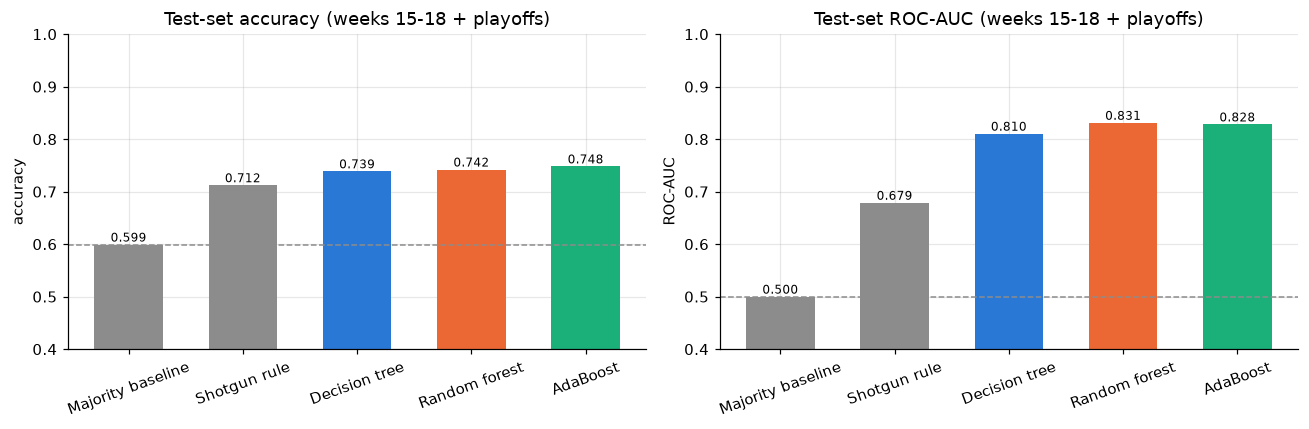

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
names = results.index.tolist()
colors = [NEUTRAL, NEUTRAL] + SERIES_COLORS[:3]
for ax, metric, floor in [(axes[0], "accuracy", 0.4), (axes[1], "ROC-AUC", 0.4)]:
    ax.bar(names, results[metric], color=colors, width=0.6)
    for i, v in enumerate(results[metric]):
        ax.text(i, v, f"{v:.3f}", ha="center", va="bottom", fontsize=8)
    ax.axhline(results.loc["Majority baseline", metric], color=NEUTRAL, ls="--", lw=1)
    ax.set(title=f"Test-set {metric} (weeks 15-18 + playoffs)", ylabel=metric, ylim=(floor, 1))
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

### 7.2 Confusion matrices (test set)
Rows = actual play type, columns = predicted play type.

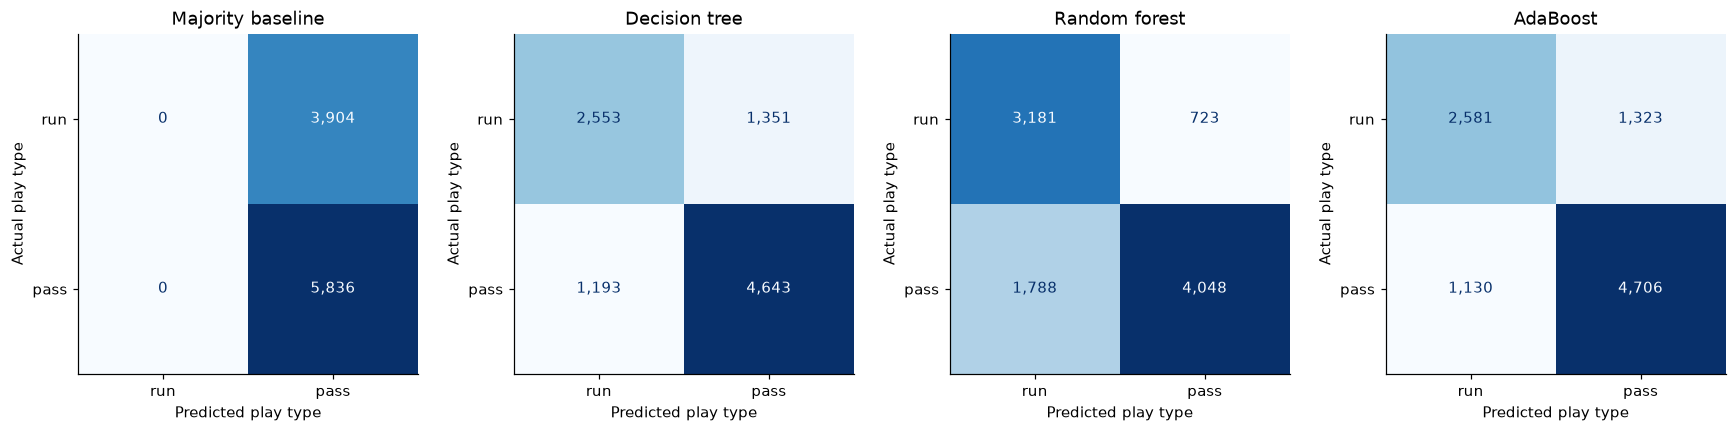

In [53]:
cm_models = ["Majority baseline", "Decision tree", "Random forest", "AdaBoost"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, name in zip(axes, cm_models):
    pred = (test_proba[name] >= 0.5).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=[0, 1]), display_labels=["run", "pass"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format=",")
    ax.set(title=name, xlabel="Predicted play type", ylabel="Actual play type")
    ax.grid(False)
plt.tight_layout()
plt.show()

**Takeaway.** The baseline never predicts a run, so its 60% accuracy comes entirely from passes. The tree and AdaBoost trade some pass recall (0.80–0.81 instead of 1.0) for catching 65–66% of runs, and still err more often by calling a run a pass. The class-weighted random forest flips that balance: 81% of runs caught but only 69% of passes. Same ranking quality, different default threshold behaviour.

### 7.3 ROC curves and the nflverse `xpass` benchmark
`xpass` is nflverse's own pass-probability model. It is **not** one of our models and was never an input; we only compare on the same test plays. We don't know exactly how it was trained, so this is a reference point, not a controlled comparison.

,accuracy,precision (pass),recall (pass),F1 (pass),recall (run),macro F1,ROC-AUC
nflverse xpass (external benchmark),0.7083,0.7493,0.7712,0.7601,0.6142,0.6941,0.7893
AdaBoost (ours),0.7482,0.7806,0.8064,0.7933,0.6611,0.7356,0.8281


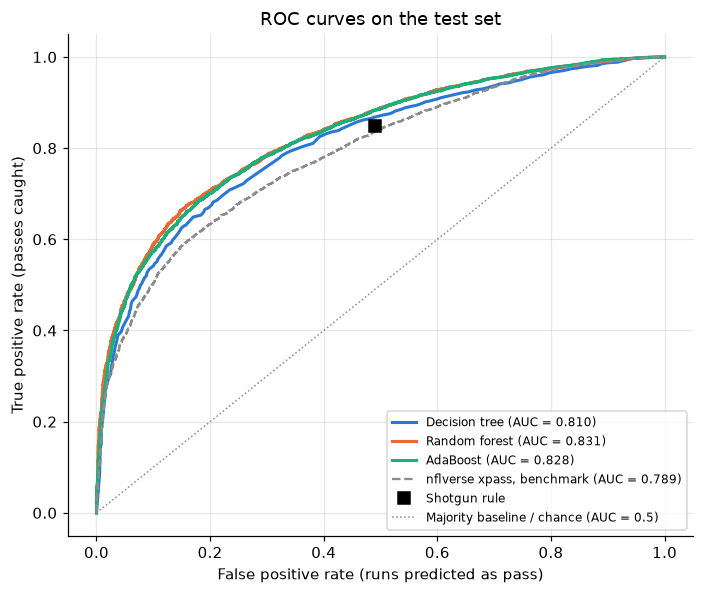

In [54]:
xpass_test = test["xpass"]
assert xpass_test.notna().all(), "xpass missing on some test plays"
xpass_row = test_metrics(y_test, xpass_test.to_numpy())
display(pd.DataFrame({"nflverse xpass (external benchmark)": xpass_row,
                      f"{best_name} (ours)": results.loc[best_name, list(xpass_row)]}).T.round(4))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
for j, name in enumerate(final_models):
    fpr, tpr, _ = roc_curve(y_test, test_proba[name])
    ax.plot(fpr, tpr, color=SERIES_COLORS[j], lw=2, label=f"{name} (AUC = {results.loc[name, 'ROC-AUC']:.3f})")
fpr, tpr, _ = roc_curve(y_test, xpass_test)
ax.plot(fpr, tpr, color=NEUTRAL, lw=1.5, ls="--", label=f"nflverse xpass, benchmark (AUC = {xpass_row['ROC-AUC']:.3f})")
shot_fpr = ((X_test["shotgun"] == 1) & (y_test == 0)).sum() / (y_test == 0).sum()
shot_tpr = ((X_test["shotgun"] == 1) & (y_test == 1)).sum() / (y_test == 1).sum()
ax.plot(shot_fpr, shot_tpr, "s", color="black", ms=8, label="Shotgun rule")
ax.plot([0, 1], [0, 1], color=NEUTRAL, lw=1, ls=":", label="Majority baseline / chance (AUC = 0.5)")
ax.set(title="ROC curves on the test set", xlabel="False positive rate (runs predicted as pass)",
       ylabel="True positive rate (passes caught)")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

**Takeaway.** Our models score higher than `xpass` on these plays (AUC 0.81–0.83 vs. 0.79; accuracy 74.8% vs. 70.8% for AdaBoost). A likely reason is that `xpass` uses only play-by-play situation, while we add formation, personnel and box count (our situation-only set A scores 0.771 in CV, §6.6). The shotgun rule's single point lies below the model curves: at the same false-positive rate, the models catch more passes.

### 7.4 Which features matter? (permutation importance)
We shuffle one input column at a time on the test set and measure how much the selected model's ROC-AUC drops (5 shuffles each). Importance shows what the model *uses*, not what makes a coach call a pass. Correlated features (e.g. the clock columns) share credit, so each can look less important than the group really is.

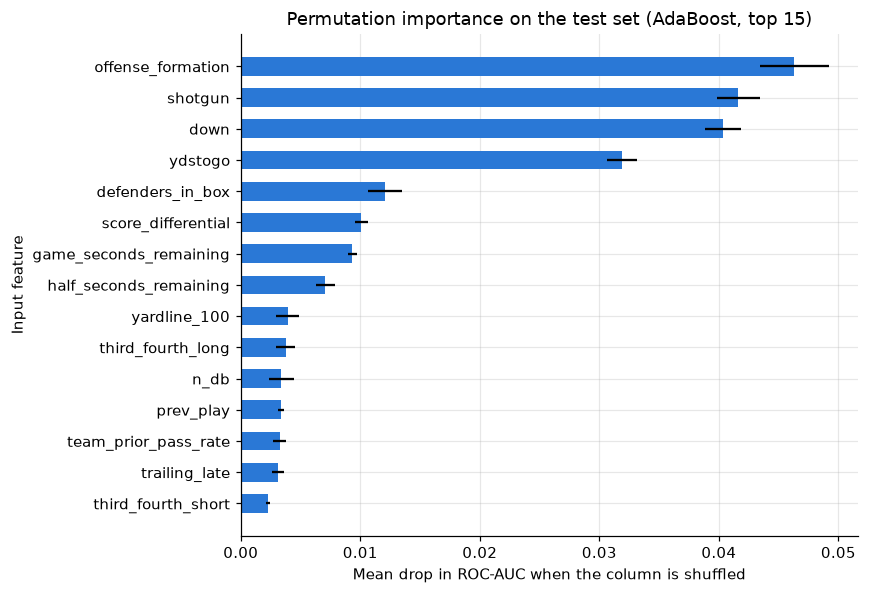

Features with ~zero importance (< 0.001): ['n_dl', 'no_huddle', 'quarter_seconds_remaining', 'posteam_timeouts_remaining', 'ydstogo_bin', 'offense_personnel', 'defense_personnel', 'defteam_timeouts_remaining', 'n_lb', 'wind', 'goal_to_go', 'is_rain', 'n_wr', 'n_rb', 'n_ol', 'red_zone', 'two_minute', 'is_home', 'is_indoor', 'qtr', 'temp', 'n_te', 'box_minus_blockers', 'drive_play_number']


In [55]:
best_pipe = final_models[best_name]
perm = permutation_importance(best_pipe, X_test, y_test, scoring="roc_auc", n_repeats=5,
                              random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({"mean AUC drop": perm.importances_mean, "std": perm.importances_std},
                   index=FEATURES).sort_values("mean AUC drop", ascending=False)

top = imp.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top.index, top["mean AUC drop"], xerr=top["std"], color=SERIES_COLORS[0], height=0.6)
ax.set(title=f"Permutation importance on the test set ({best_name}, top 15)",
       xlabel="Mean drop in ROC-AUC when the column is shuffled", ylabel="Input feature")
plt.tight_layout()
plt.show()
print("Features with ~zero importance (< 0.001):", imp.index[imp["mean AUC drop"] < 0.001].tolist())

**Takeaway.** The model relies mostly on **alignment** (`offense_formation`, `shotgun`, `defenders_in_box`) and **down & distance**, then score and clock. Personnel strings and counts show ~zero importance individually, largely because they overlap with formation, shotgun and box count; as a group, alignment information clearly matters (A → B in §6.6). Weather features contribute essentially nothing, matching §3.5.

### 7.5 Error analysis
For each group we compare the selected model's test accuracy with the majority baseline's (which equals the group's pass share).

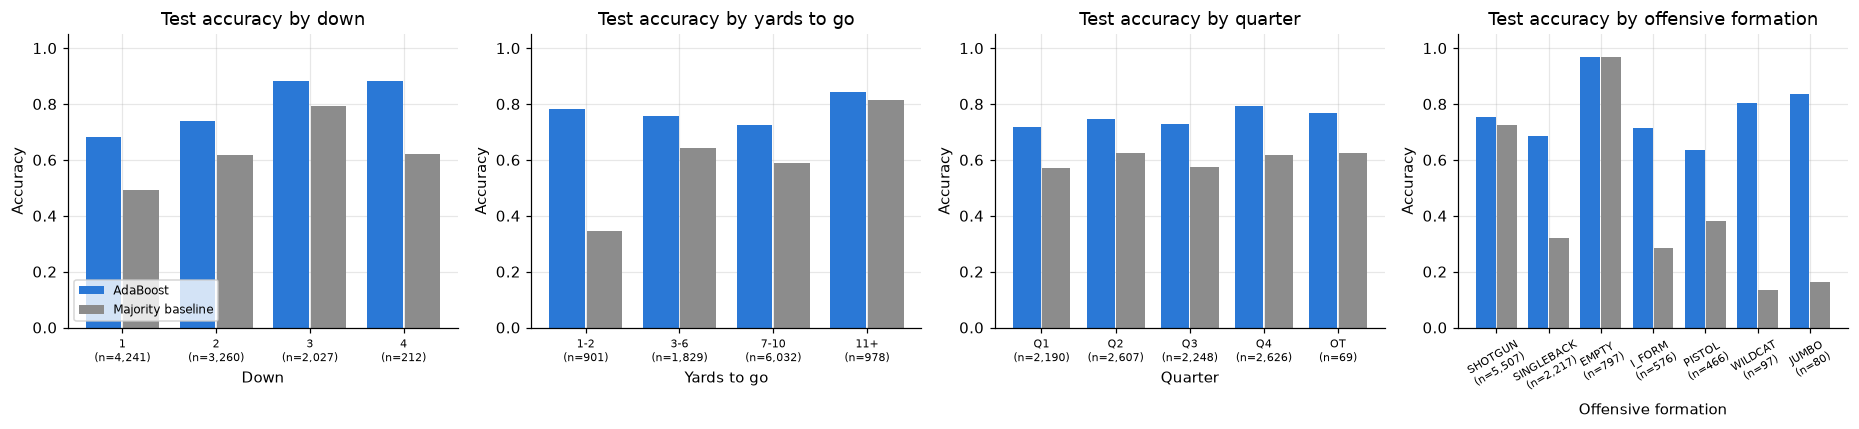


Down:
            plays  pass_rate  model_acc  baseline_acc
down_label                                           
1            4241      0.491      0.683         0.491
2            3260      0.618      0.740         0.618
3            2027      0.794      0.883         0.794
4             212      0.623      0.882         0.623

Yards to go:
             plays  pass_rate  model_acc  baseline_acc
ydstogo_bin                                           
1-2            901      0.344      0.782         0.344
3-6           1829      0.644      0.758         0.644
7-10          6032      0.589      0.725         0.589
11+            978      0.814      0.842         0.814

Quarter:
         plays  pass_rate  model_acc  baseline_acc
quarter                                           
Q1        2190      0.571      0.717         0.571
Q2        2607      0.624      0.746         0.624
Q3        2248      0.574      0.728         0.574
Q4        2626      0.618      0.793         0.618
OT       

In [56]:
err = test.assign(proba=test_proba[best_name])
err["pred"] = (err["proba"] >= 0.5).astype(int)
err["correct"] = (err["pred"] == err[TARGET]).astype(int)
err["baseline_correct"] = (err[TARGET] == majority_class).astype(int)
err["down_label"] = err["down"].astype(int).astype(str)
err["quarter"] = err["qtr"].astype(int).map({1: "Q1", 2: "Q2", 3: "Q3", 4: "Q4", 5: "OT"})

def by_group(col, order=None):
    g = err.groupby(col, observed=True).agg(plays=("correct", "size"), pass_rate=(TARGET, "mean"),
                                            model_acc=("correct", "mean"), baseline_acc=("baseline_correct", "mean"))
    return g.reindex(order) if order else g

groups_to_plot = [("down_label", "Down", ["1", "2", "3", "4"]),
                  ("ydstogo_bin", "Yards to go", YTG_LABELS),
                  ("quarter", "Quarter", ["Q1", "Q2", "Q3", "Q4", "OT"]),
                  ("offense_formation", "Offensive formation", None)]
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, (col, label, order) in zip(axes, groups_to_plot):
    g = by_group(col, order)
    if order is None:
        g = g.sort_values("plays", ascending=False)
    xs = np.arange(len(g))
    ax.bar(xs - 0.2, g["model_acc"], width=0.38, color=SERIES_COLORS[0], label=best_name)
    ax.bar(xs + 0.2, g["baseline_acc"], width=0.38, color=NEUTRAL, label="Majority baseline")
    ax.set_xticks(xs, [f"{i}\n(n={n:,})" for i, n in zip(g.index, g["plays"])], fontsize=7,
                  rotation=30 if order is None else 0)
    ax.set(title=f"Test accuracy by {label.lower()}", xlabel=label, ylabel="Accuracy", ylim=(0, 1.05))
axes[0].legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

summary_tables = {label: by_group(col, order) for col, label, order in groups_to_plot}
for label, g in summary_tables.items():
    print(f"\n{label}:")
    print(g.round(3).to_string())

In [57]:
# situations combining down and distance: where are the most errors in absolute terms?
dd = err.groupby(["down_label", "ydstogo_bin"], observed=True).agg(
    plays=("correct", "size"), pass_rate=(TARGET, "mean"), model_acc=("correct", "mean"),
    errors=("correct", lambda s: int((1 - s).sum())))
dd["share_of_all_errors"] = dd["errors"] / dd["errors"].sum()
print(f"Total test errors: {dd['errors'].sum():,} of {len(err):,} plays")
dd.sort_values("errors", ascending=False).head(8).round(3)

Total test errors: 2,453 of 9,740 plays


plays  pass_rate  model_acc  errors  \
down_label ydstogo_bin                                        
1          7-10          3912      0.490      0.679    1254   
2          7-10          1501      0.707      0.753     370   
           3-6            973      0.497      0.674     317   
3          1-2            433      0.379      0.755     106   
2          11+            470      0.777      0.798      95   
3          3-6            663      0.882      0.894      70   
2          1-2            316      0.329      0.797      64   
1          3-6            133      0.406      0.632      49   

                        share_of_all_errors  
down_label ydstogo_bin                       
1          7-10                       0.511  
2          7-10                       0.151  
           3-6                        0.129  
3          1-2                        0.043  
2          11+                        0.039  
3          3-6                        0.029  
2          1-2                        0.026  
1          3-6                        0.020

In [58]:
# most confident mistakes
show = ["week", "posteam", "defteam", "qtr", "down", "ydstogo", "yardline_100", "score_differential",
        "half_seconds_remaining", "offense_formation", "offense_personnel", "defenders_in_box", "shotgun", TARGET, "proba"]
print(f"{best_name} test scores range from {err['proba'].min():.3f} to {err['proba'].max():.3f}")
wrong = err[err["correct"] == 0].assign(confidence=lambda d: (d["proba"] - 0.5).abs())
wrong.sort_values("confidence", ascending=False)[show].head(8).round(3)

AdaBoost test scores range from 0.276 to 0.813


,week,posteam,defteam,qtr,down,ydstogo,yardline_100,score_differential,half_seconds_remaining,offense_formation,offense_personnel,defenders_in_box,shotgun,is_pass,proba
9435,21,CIN,KC,3.0,3.0,6.0,42.0,-7.0,1560.0,EMPTY,"1 RB, 1 TE, 3 WR",4.0,1.0,0,0.747
579,15,JAX,DAL,2.0,3.0,10.0,65.0,-14.0,6.0,SHOTGUN,"1 RB, 1 TE, 3 WR",3.0,1.0,0,0.743
1493,15,NYG,WAS,1.0,2.0,11.0,65.0,-3.0,943.0,EMPTY,"1 RB, 1 TE, 3 WR",6.0,1.0,0,0.734
9664,22,PHI,KC,2.0,4.0,5.0,44.0,0.0,328.0,EMPTY,"1 RB, 1 TE, 3 WR",5.0,1.0,0,0.733
1650,15,PHI,CHI,2.0,3.0,8.0,22.0,-3.0,48.0,EMPTY,"1 RB, 1 TE, 3 WR",6.0,1.0,0,0.733
9656,22,PHI,KC,2.0,3.0,5.0,51.0,7.0,588.0,EMPTY,"1 RB, 1 TE, 3 WR",5.0,1.0,0,0.730
1258,15,BUF,MIA,2.0,2.0,10.0,82.0,1.0,171.0,EMPTY,"1 RB, 1 TE, 3 WR",5.0,1.0,0,0.727
9524,21,PHI,SF,1.0,2.0,9.0,73.0,7.0,960.0,EMPTY,"1 RB, 1 TE, 3 WR",5.0,1.0,0,0.722


**Takeaway.**
- **Early downs and "balanced" situations are hardest.** 1st down with 7–10 yards (49% pass) produces **51% of all test errors** at 68% accuracy. 3rd down, where the call is more predictable, reaches 88%.
- **Where the model adds most over the baseline:** short yardage (78% vs. 34%), under-center formations (I-form 71% vs. 28%, singleback 69% vs. 32%), and the 4th quarter (79% vs. 62%).
- **Where it adds least:** shotgun (75% vs. 72%), long distance (11+: 84% vs. 81%) and EMPTY (97%, same as the baseline). These groups lean so heavily to pass that there's little room above the baseline. Shotgun runs are the main blind spot.
- **The highest-scored mistakes** are all shotgun/empty sets with 11 personnel and 3–6 box defenders that were actually runs (e.g. draws or QB runs from passing looks). Pre-snap data can't see a run designed to look like a pass. AdaBoost's scores fall in a narrow band (printed above), so they rank plays well but should not be read as calibrated probabilities.

### 7.6 Sensitivity check: penalty-nullified plays
We kept plays wiped out by a penalty (§2.1). Two checks:
1. **Training choice (CV only):** train with vs. without them; validation always excludes them.
2. **Final model on the test set:** all test plays vs. test plays without them (nothing is refit).

In [59]:
assert "is_nullified" not in FEATURES
keep_tr, keep_te = (train["is_nullified"] == 0).to_numpy(), (test["is_nullified"] == 0).to_numpy()
print(f"nullified plays: train {(~keep_tr).sum():,}, test {(~keep_te).sum():,}")

# 1) CV: same folds, validation always without nullified plays; training with vs. without them
cv_rows = {}
for label, use_train in [("trained with nullified", np.ones(len(train), bool)), ("trained without nullified", keep_tr)]:
    aucs = []
    for tr_idx, va_idx in cv:
        tr_idx, va_idx = tr_idx[use_train[tr_idx]], va_idx[keep_tr[va_idx]]
        model = clone(best_pipe).fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
        aucs.append(roc_auc_score(y_train.iloc[va_idx], model.predict_proba(X_train.iloc[va_idx])[:, 1]))
    cv_rows[label] = {"CV ROC-AUC (validation w/o nullified)": np.mean(aucs)}
display(pd.DataFrame(cv_rows).T.round(4))

# 2) final model, test subgroup
pd.DataFrame({"test, all plays": test_metrics(y_test, test_proba[best_name]),
              "test w/o nullified": test_metrics(y_test[keep_te], test_proba[best_name][keep_te])}).T[
    ["accuracy", "F1 (pass)", "ROC-AUC"]].round(4)

nullified plays: train 1,062, test 313


,CV ROC-AUC (validation w/o nullified)
trained with nullified,0.8268
trained without nullified,0.8255


,accuracy,F1 (pass),ROC-AUC
"test, all plays",0.7482,0.7933,0.8281
test w/o nullified,0.7483,0.7922,0.8292


**Takeaway.** Keeping penalty-nullified plays does not hurt. In CV, training with them scores 0.8268 vs. 0.8255 without (validation always excludes them), a gap below one fold standard deviation. On the test set the final model scores the same accuracy and nearly the same AUC with or without them (0.828 vs. 0.829). The §2.1 decision stands.

### 7.7 Conclusions

- Every trained model beats guessing the majority class (pass): **~74–75% vs. 60% test accuracy**, ROC-AUC 0.81–0.83 vs. 0.50. All models also beat the shotgun rule (71%), and on our test plays they score above nflverse's `xpass` (AUC 0.79).
- **Model choice mattered less than inputs and regularization.** A constrained single tree reaches 0.81 AUC; the two ensembles score ~0.83 and are effectively tied in CV. The largest measured gain came from **merging the participation data** (+0.05 CV AUC). Our engineered features added a smaller, less certain ~0.005.
- **Methodology note.** Cross-validation is forward-chaining by week, because the team-tendency feature uses earlier weeks' labels. Ordinary `GroupKFold` would let validation labels leak into training features (§5).
- **Limits.** The model reads at-snap alignment, which partly reflects the defense's *own* reaction (box count). It struggles on 1st-and-10 and with runs from passing formations. It is trained on one season, so tendencies may shift across seasons.